# *Dataset: Student Alcohol Consumption*

Os dados foram obtidos por meio de uma pesquisa com estudantes do ensino secundário que cursavam Matemática e Língua Portuguesa. O conjunto de dados contém diversas **informações sobre os aspectos sociais, o gênero e os hábitos de estudo dos estudantes.**

# *Dicionário*

Atributos presentes nos dois conjuntos de dados: `student-mat.csv` (curso de Matemática) e `student-por.csv` (curso de Língua Portuguesa).

1. escola — Escola do estudante (binária: `'GP'` — Gabriel Pereira ou `'MS'` — Mousinho da Silveira).

2. sexo — Sexo do estudante (binária: `'F'` — feminino ou `'M'` — masculino).

3. idade — Idade do estudante (numérica: de 15 a 22 anos).

4. regiao — Tipo de endereço residencial do estudante (binária: `'U'` — urbano ou `'R'` — rural).

5. tamanho_familia — Tamanho da família (binária: `'LE3'` — menor ou igual a 3 pessoas ou `'GT3'` — maior que 3 pessoas).

6. convivencia_pais — Situação de convivência dos pais (binária: `'T'` — moram juntos ou `'A'` — moram separados).

7. educacao_mae — Escolaridade da mãe (numérica: 0 — nenhuma; 1 — ensino primário, equivalente à 4ª série; 2 — do 5º ao 9º ano; 3 — ensino secundário; ou 4 — ensino superior).

8. educacao_pai — Escolaridade do pai (numérica: 0 — nenhuma; 1 — ensino primário, equivalente à 4ª série; 2 — do 5º ao 9º ano; 3 — ensino secundário; ou 4 — ensino superior).

9. trabalho_mae — Profissão da mãe (categórica nominal: `'teacher'` — professora; `'health'` — área da saúde; `'services'` — serviços públicos, como administração ou polícia; `'at_home'` — trabalha em casa; ou `'other'` — outra profissão).

10. trabalho_pai — Profissão do pai (categórica nominal: `'teacher'` — professor; `'health'` — área da saúde; `'services'` — serviços públicos, como administração ou polícia; `'at_home'` — trabalha em casa; ou `'other'` — outra profissão).

11. escolha_escola — Motivo para escolher a escola (categórica nominal: proximidade de `'home'` — casa; reputação da escola (`'reputation'`); preferência pelo curso (`'course'`); ou outro motivo (`'other'`)).

12. guardiao_legal — Responsável legal pelo estudante (categórica nominal: `'mother'` — mãe; `'father'` — pai; ou `'other'` — outro).

13. tempo_viagem_escola — Tempo de deslocamento de casa até a escola (numérica: 1 — menos de 15 minutos; 2 — de 15 a 30 minutos; 3 — de 30 minutos a 1 hora; ou 4 — mais de 1 hora).

14. tempo_estudo_semanal — Tempo semanal de estudo (numérica: 1 — menos de 2 horas; 2 — de 2 a 5 horas; 3 — de 5 a 10 horas; ou 4 — mais de 10 horas).

15. nº_reprovacoes — Número de reprovações anteriores (numérica: indica o número de reprovações quando 1≤n<31 \leq n < 31≤n<3; caso contrário, o valor é 4).

16. apoio_escola — Recebe apoio educacional extra da escola (binária: sim ou não).

17. apoio_familiar — Recebe apoio educacional da família (binária: sim ou não).

18. paid — Participa de aulas particulares pagas na disciplina correspondente (Matemática ou Língua Portuguesa) (binária: sim ou não).

19. participacao_atividades_extras — Participa de atividades extracurriculares (binária: sim ou não).

20. edu_infantil — Frequentou a educação infantil (binária: sim ou não).

21. desejo_de_ensino superior — Deseja cursar o ensino superior (binária: sim ou não).

22. acesso_internet_casa — Possui acesso à internet em casa (binária: sim ou não).

23. relacionamento_amoroso — Está em um relacionamento amoroso (binária: sim ou não).

24. qualidade_relacao_familiar — Qualidade das relações familiares (numérica: de 1 — muito ruim a 5 — excelente).

25. tempo_livre — Tempo livre após as aulas (numérica: de 1 — muito baixo a 5 — muito alto).

26. frequencia_saida_com_amigos — Frequência com que sai com os amigos (numérica: de 1 — muito baixa a 5 — muito alta).

27. consumo_alcool_semana — Consumo de álcool durante os dias úteis (numérica: de 1 — muito baixo a 5 — muito alto).

28. consumo_alcool_fim_de_semana — Consumo de álcool durante os fins de semana (numérica: de 1 — muito baixo a 5 — muito alto).

29. estado_saude_atual — Estado de saúde atual (numérica: de 1 — muito ruim a 5 — muito bom).

30. faltas — Número de faltas escolares (numérica: de 0 a 93).

31. nota_1p — Nota do primeiro período (numérica: de 0 a 20).

32. nota_2p — Nota do segundo período (numérica: de 0 a 20).

33. nota_final — Nota final (numérica: de 0 a 20; variável-alvo para previsão).

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import numpy as np

In [2]:
df_port = pd.read_csv('files/student-por.csv')
df_mat = pd.read_csv('files/student-mat.csv')

In [3]:
# Retirando algumas colunas.
df_port = df_port.drop(columns=['traveltime', 'schoolsup', 'paid', 'nursery'])
df_mat = df_mat.drop(columns=['traveltime', 'schoolsup', 'paid', 'nursery'])

# Renomeando as colunas sobrantes:
df_port = df_port.rename(columns={
    'school': 'escola',
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'absences': 'faltas',
    'famsize': 'tamanho_familia',
    'Pstatus': 'convivencia_pais',
    'Medu': 'educacao_mae',
    'Fedu': 'educacao_pai',
    'Mjob': 'trabalho_mae',
    'Fjob': 'trabalho_pai',
    'reason': 'motivo_escola',
    'guardian': 'guardiao_legal',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'famsup': 'apoio_familiar',
    'activities': 'participacao_atividades_extras',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final'
})

df_mat = df_mat.rename(columns={
    'school': 'escola',
    'sex': 'sexo',
    'age': 'idade',
    'address': 'regiao',
    'absences': 'faltas',
    'famsize': 'tamanho_familia',
    'Pstatus': 'convivencia_pais',
    'Medu': 'educacao_mae',
    'Fedu': 'educacao_pai',
    'Mjob': 'trabalho_mae',
    'Fjob': 'trabalho_pai',
    'reason': 'motivo_escola',
    'guardian': 'guardiao_legal',
    'studytime': 'tempo_semanal_estudo',
    'failures': 'nº_reprovacoes',
    'famsup': 'apoio_familiar',
    'activities': 'participacao_atividades_extras',
    'higher': 'desejo_de_ensino_superior',
    'internet': 'acesso_internet_casa',
    'romantic': 'relacionamento_amoroso',
    'famrel': 'qualidade_relacao_familiar',
    'freetime': 'tempo_livre',
    'goout': 'frequencia_saida_com_amigos',
    'Dalc': 'consumo_alcool_semana',
    'Walc': 'consumo_alcool_fim_de_semana',
    'health': 'estado_saude_atual',
    'G1': 'nota_1p',
    'G2': 'nota_2p',
    'G3': 'nota_final'
})


## Boxplots que geram os quartis das variáveis nominais por dataframe


In [4]:
def boxplots_provas(df, col_notas, nominais, disciplina="", mostrar_tabelas=False):
    for col in nominais:
        ordem = sorted(df[col].dropna().unique())            # ordem fixa das categorias
        contagem = df[col].value_counts()
        rotulos = [f"{c}\n(n={contagem[c]})" for c in ordem]  # quantos alunos há em cada caixa

        fig, axes = plt.subplots(1, len(col_notas), figsize=(5.5 * len(col_notas), 4), sharey=True)
        axes = np.atleast_1d(axes)

        for ax, nota in zip(axes, col_notas):
            sns.boxplot(data=df, x=col, y=nota, order=ordem, ax=ax)
            ax.set_xticks(range(len(ordem)))
            ax.set_xticklabels(rotulos)
            ax.set_title(nota)
            ax.set_xlabel("")

            if mostrar_tabelas:
                print(f"\n===== {disciplina} | {nota} por {col} =====")
                print(df.groupby(col)[nota].describe().round(1))

        fig.suptitle(f"{disciplina} - notas por {col}", fontsize=14)
        plt.tight_layout(rect=[0, 0, 1, 0.94])
        plt.show()

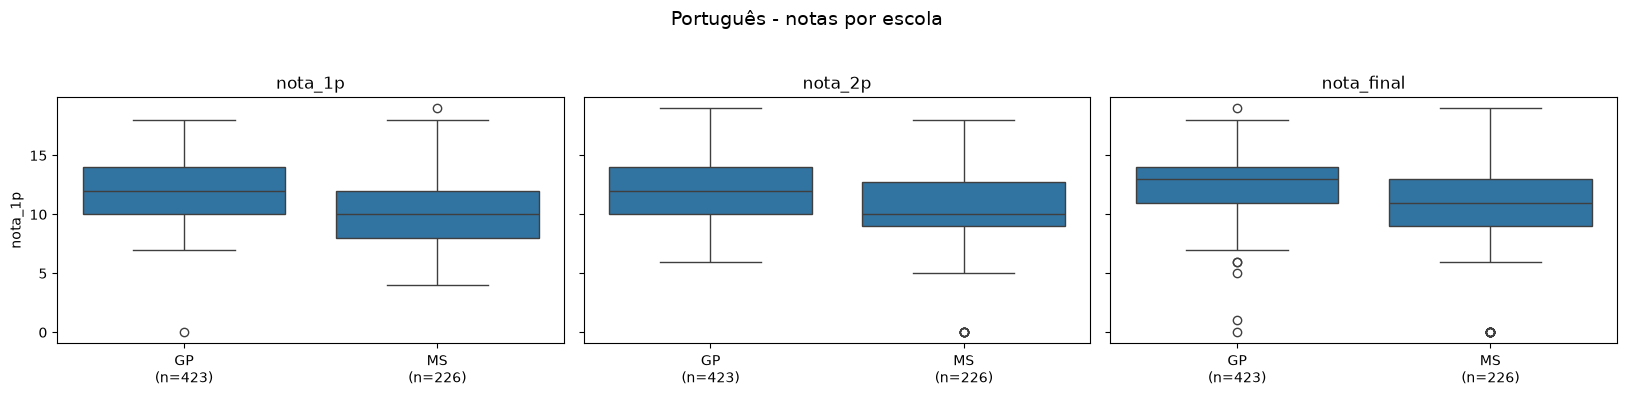

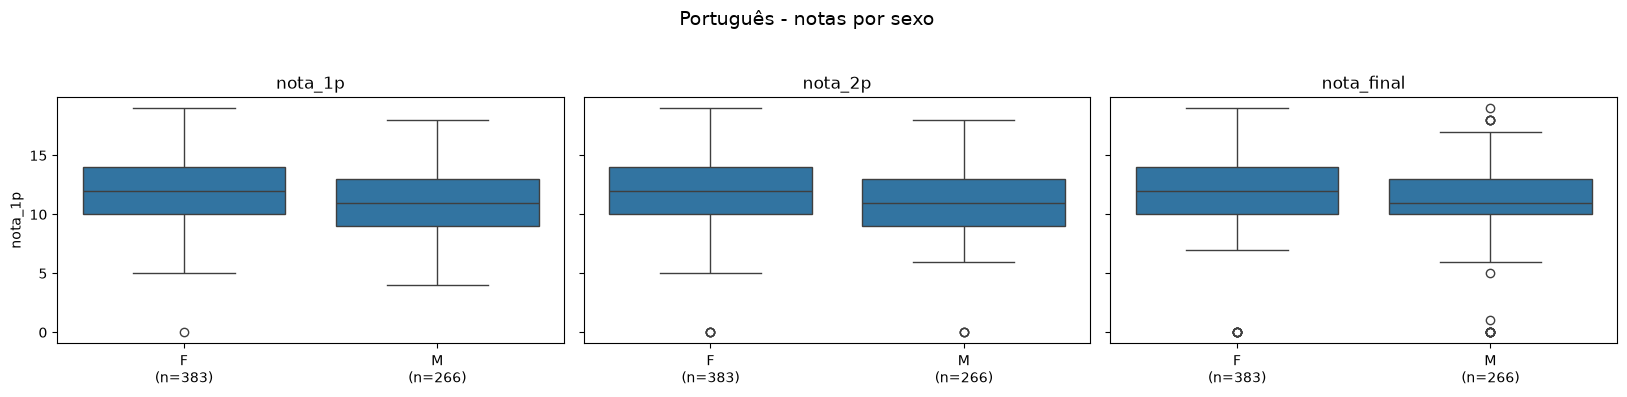

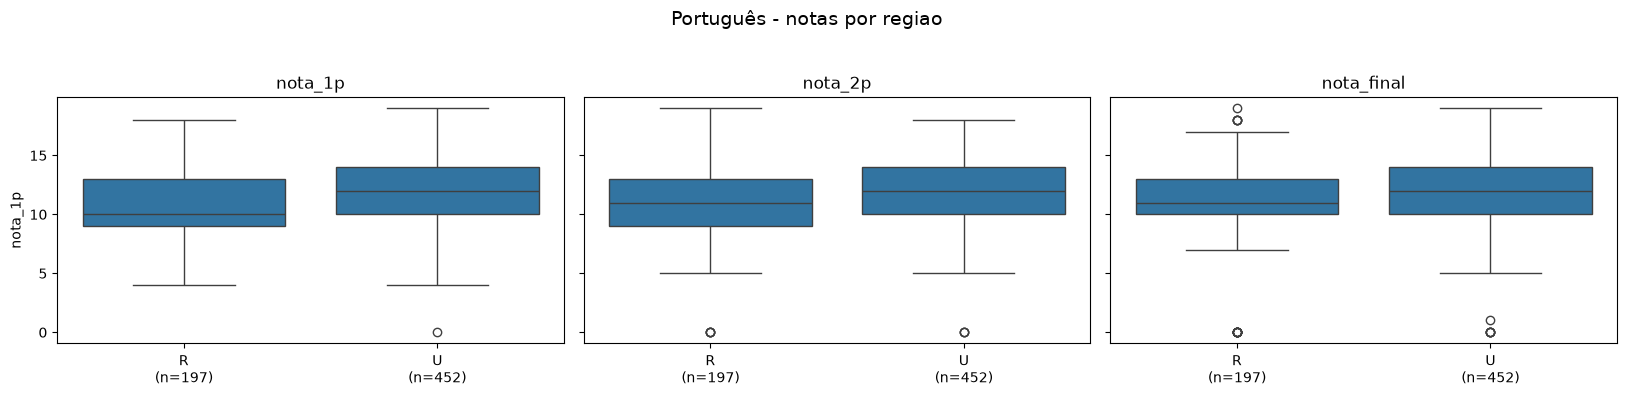

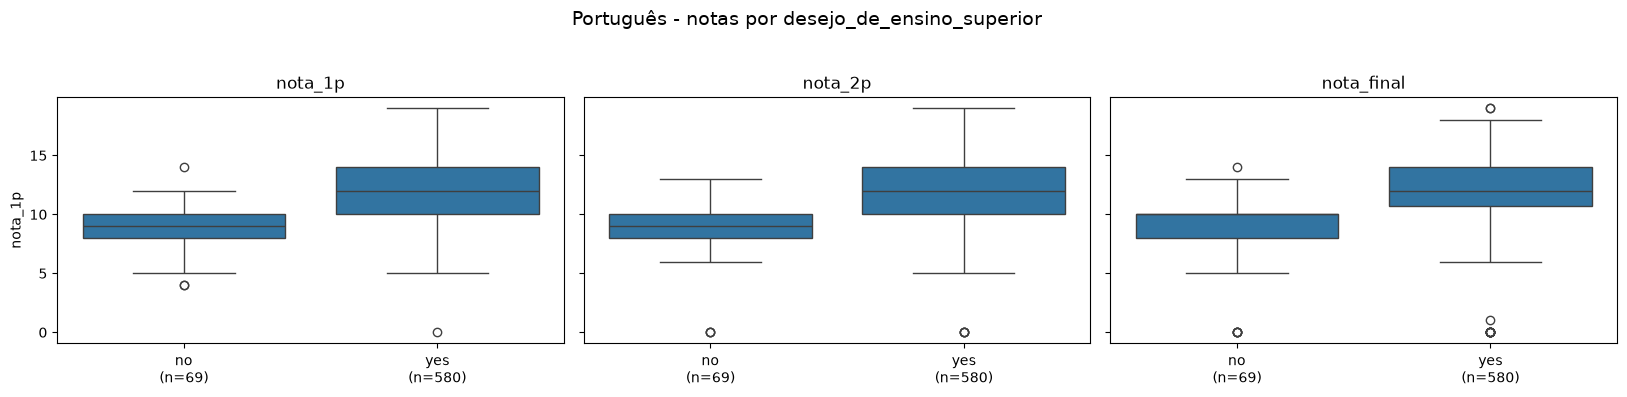

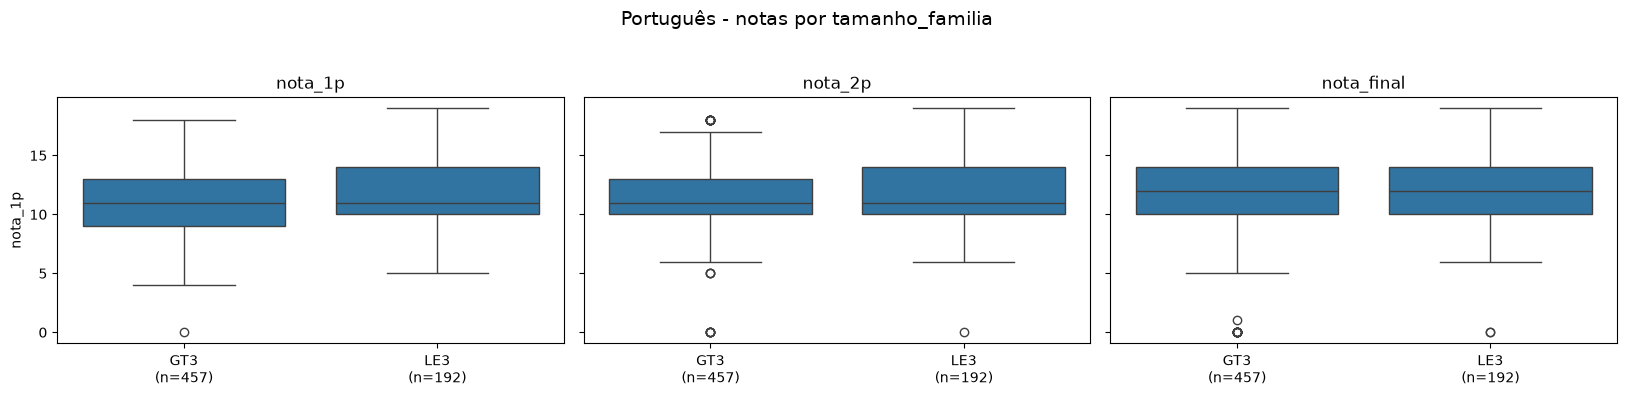

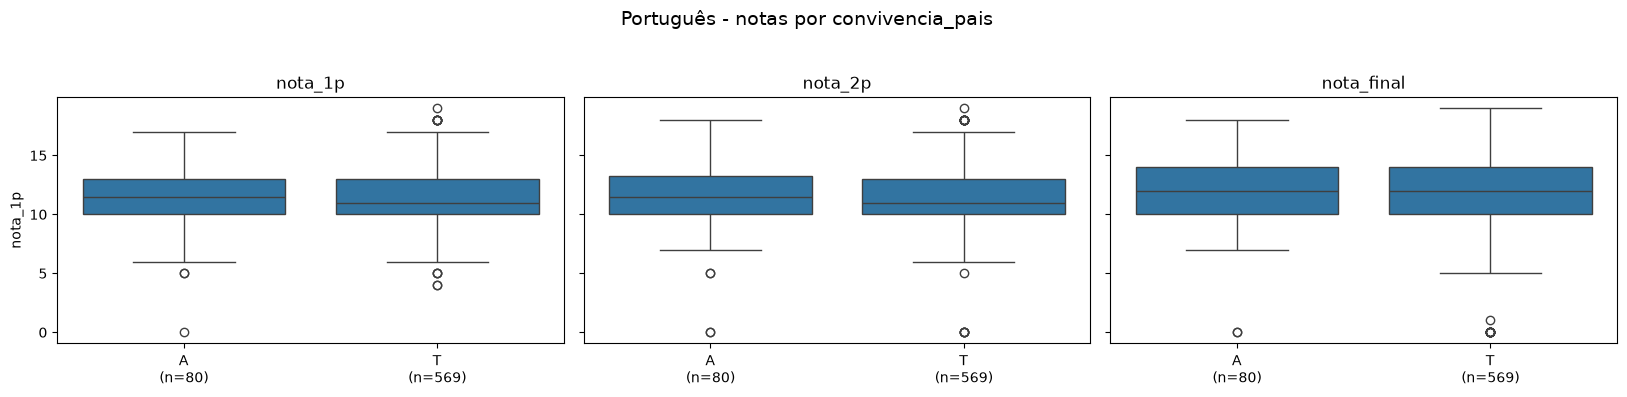

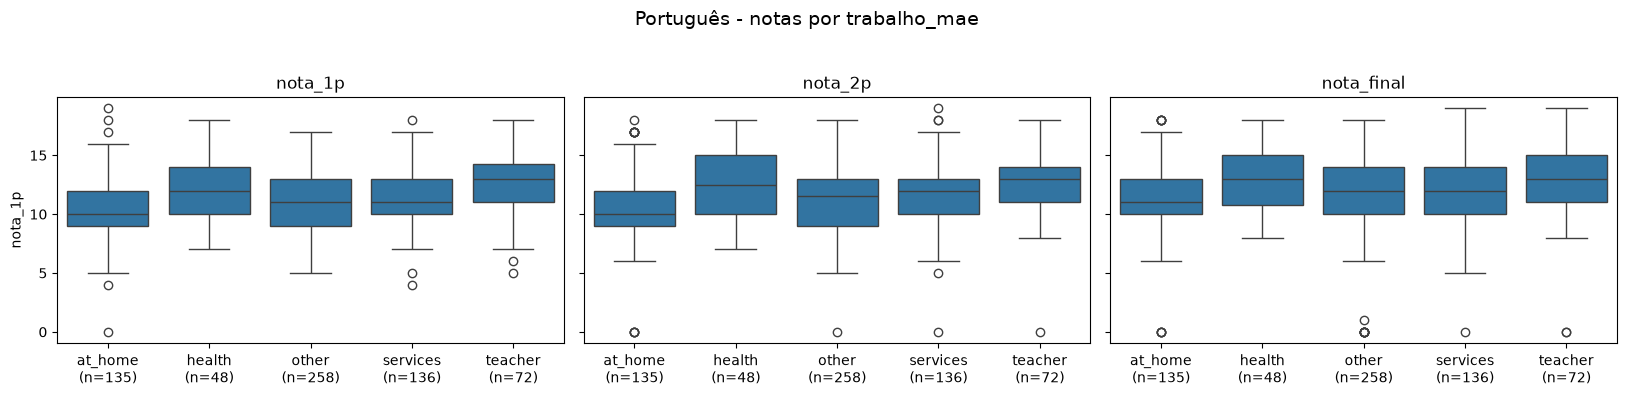

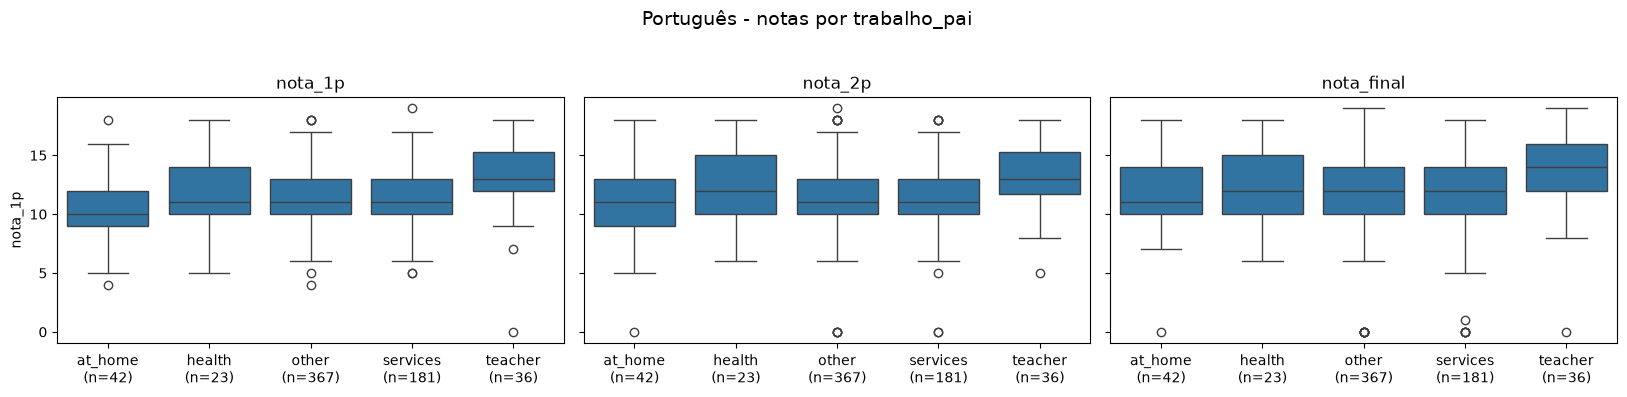

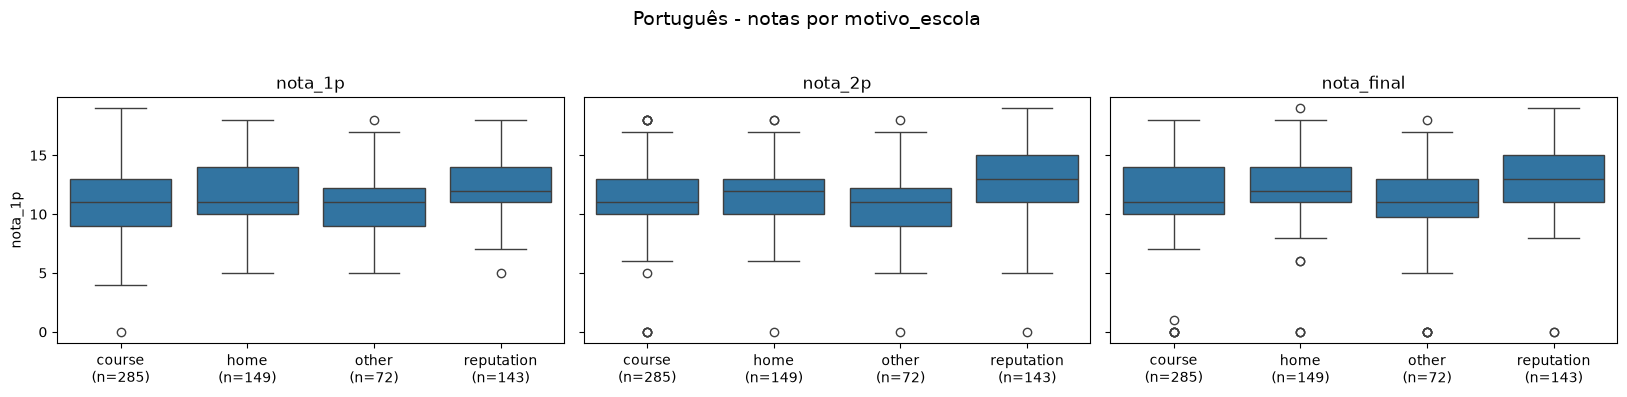

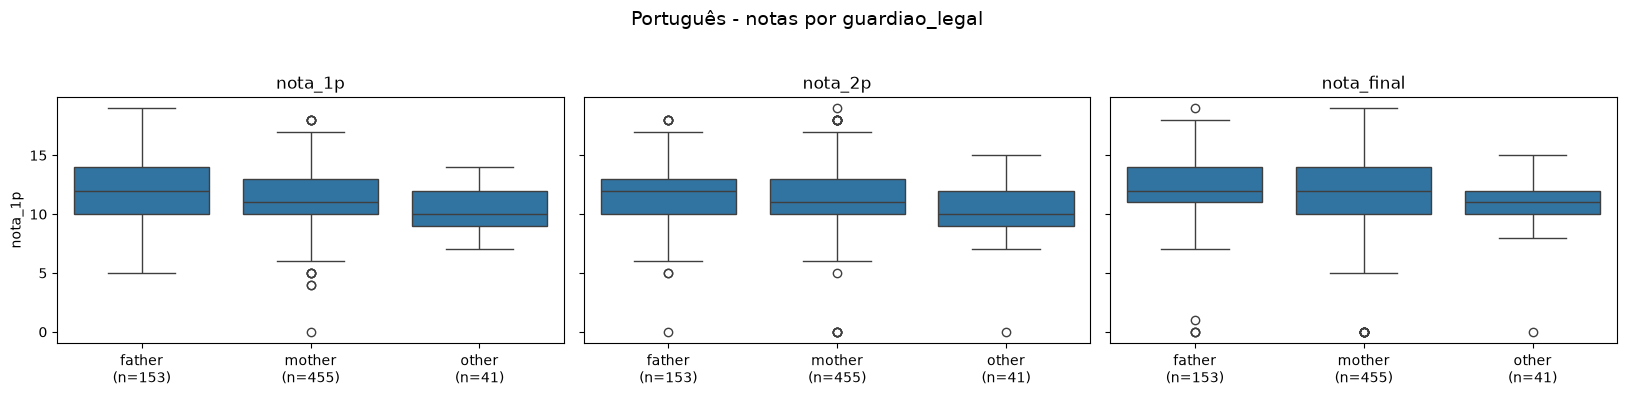

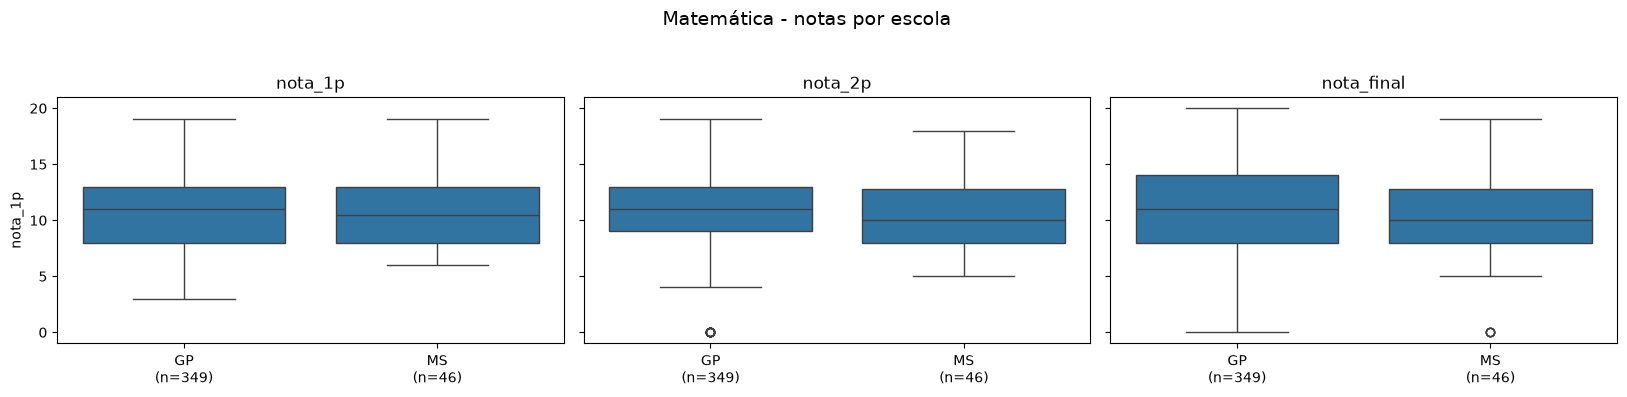

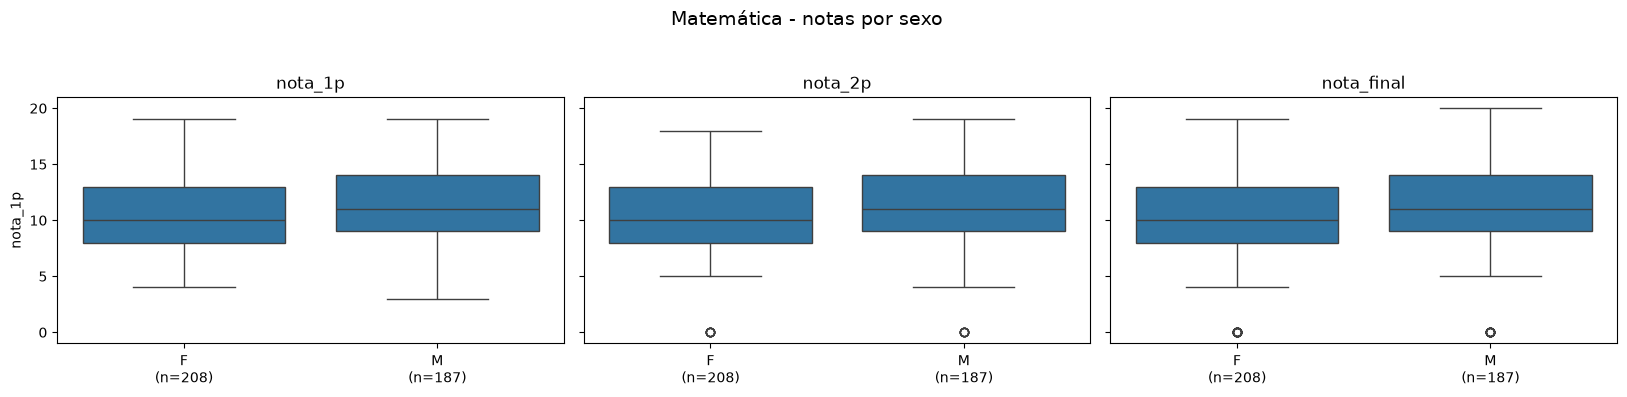

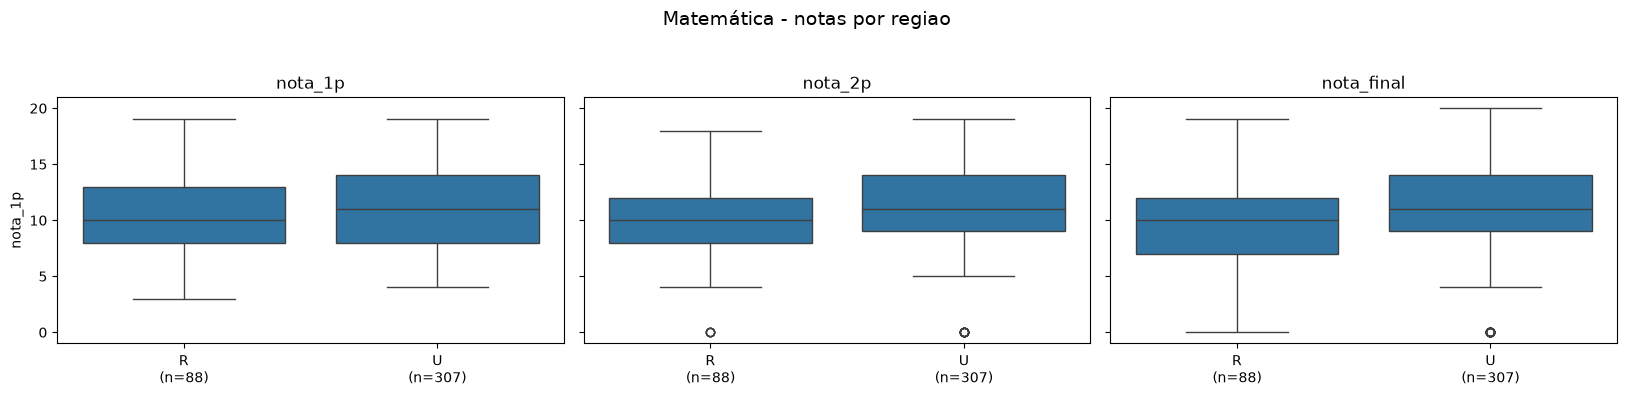

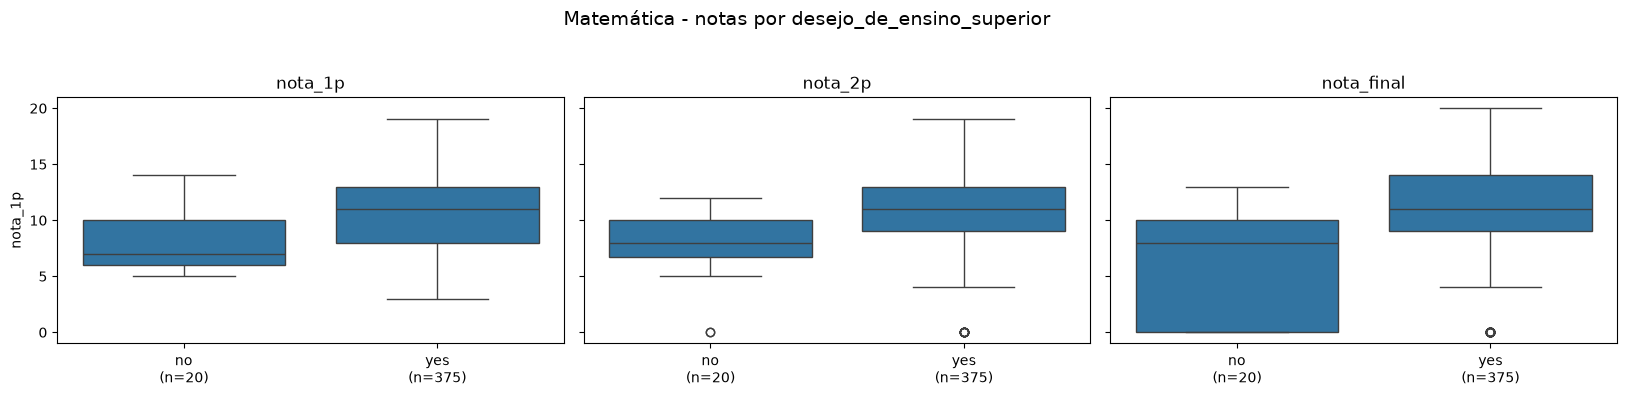

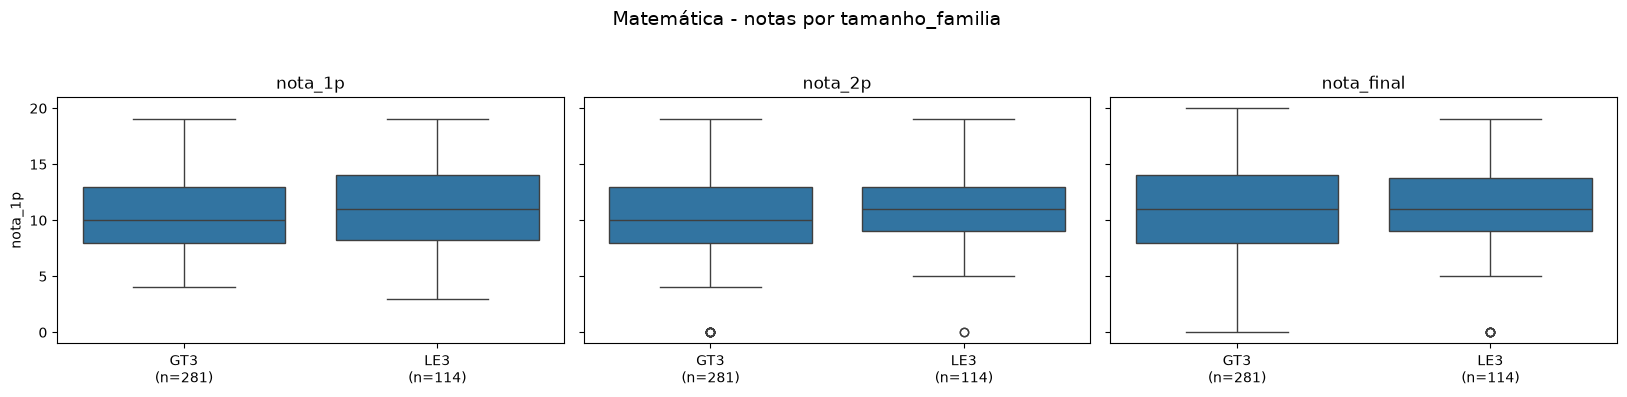

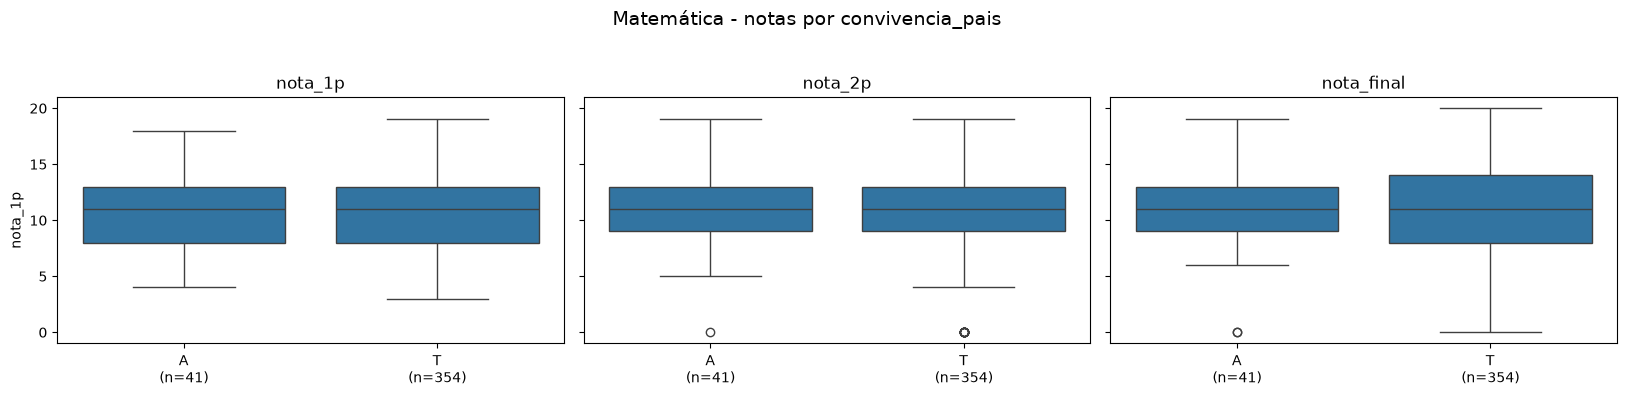

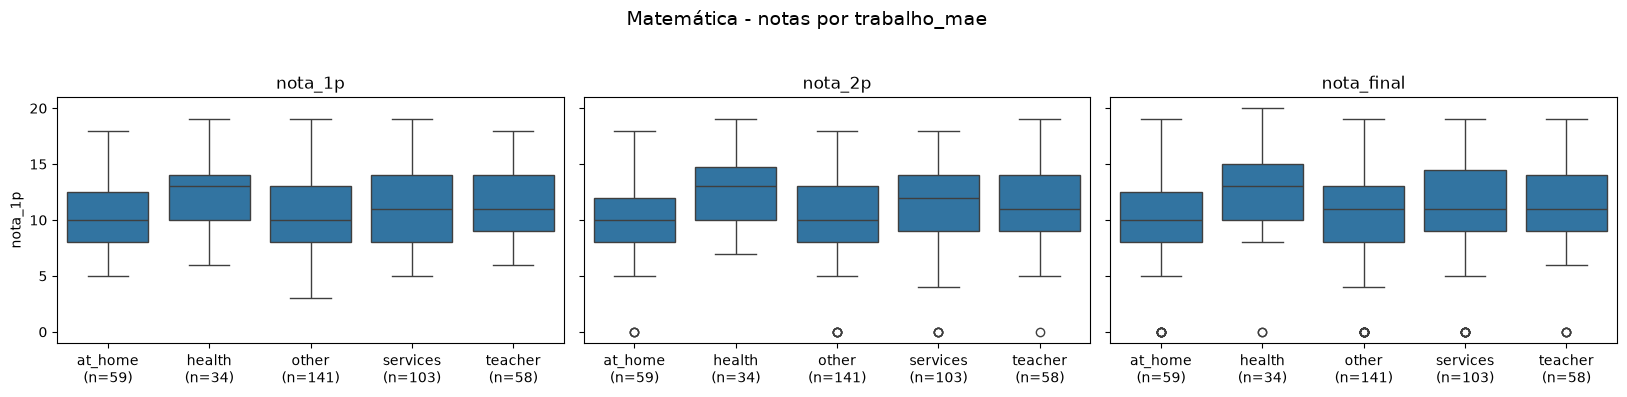

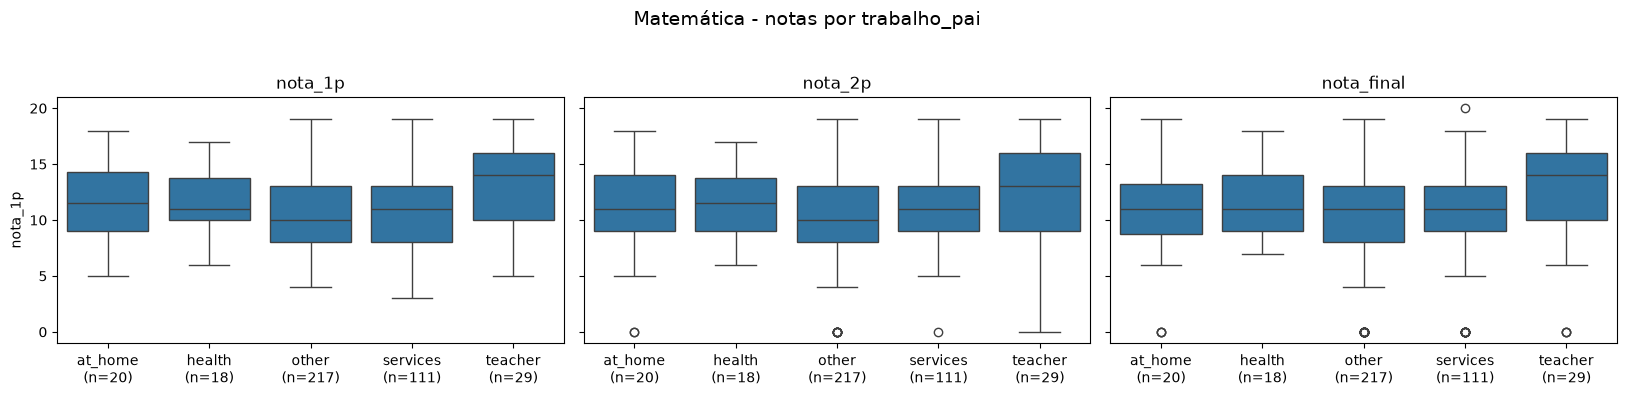

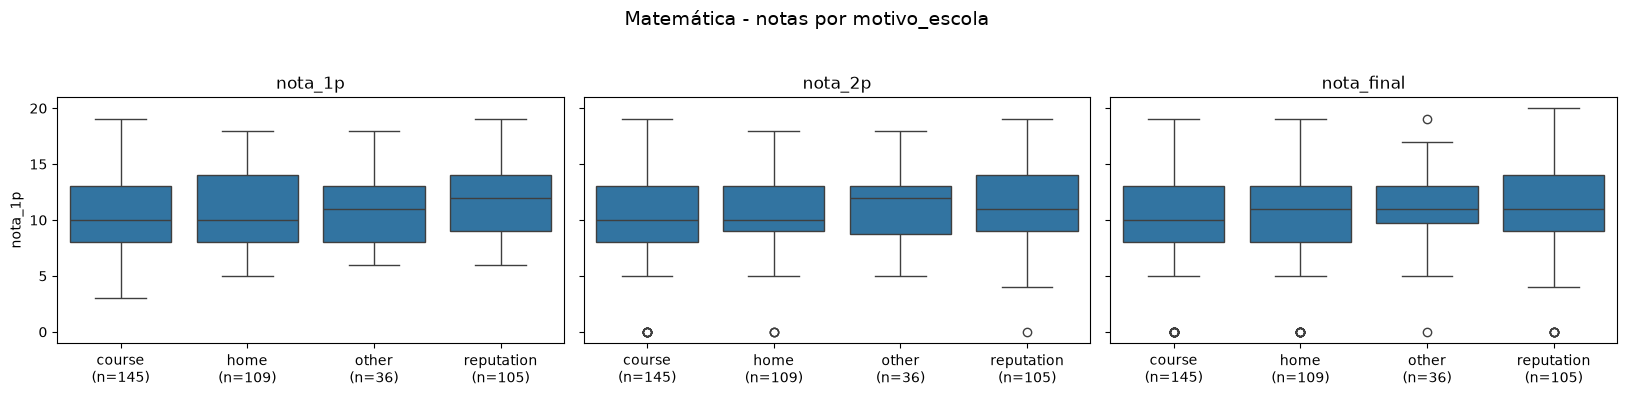

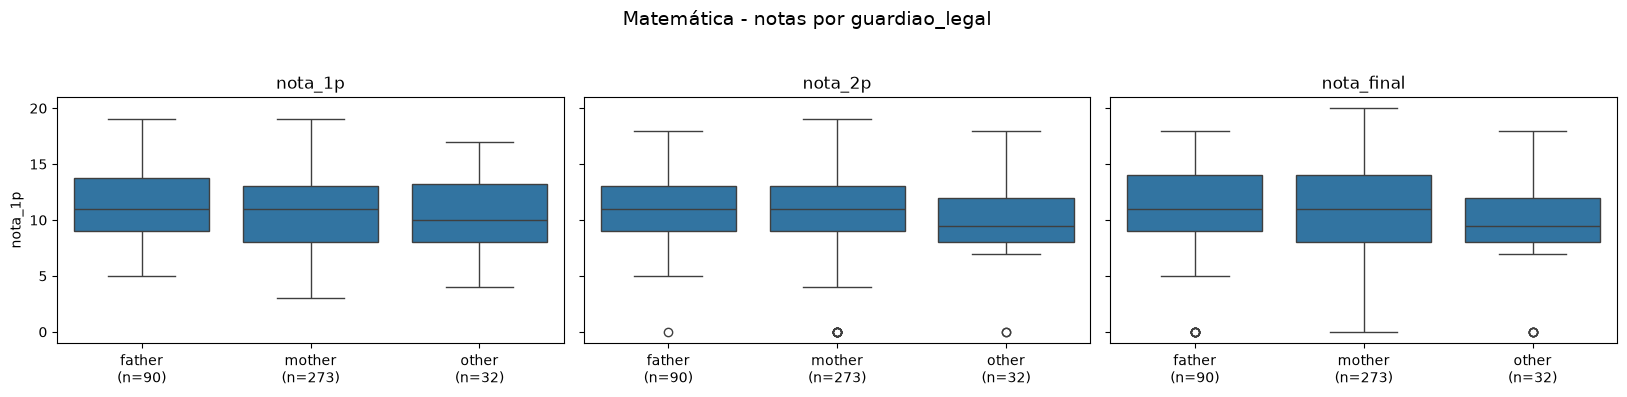

In [5]:
nominais = ["escola", "sexo", "regiao", "desejo_de_ensino_superior", "tamanho_familia",
            "convivencia_pais", "trabalho_mae", "trabalho_pai", "motivo_escola", "guardiao_legal"]
notas = ["nota_1p", "nota_2p", "nota_final"]

boxplots_provas(df_port, notas, nominais, disciplina="Português")
boxplots_provas(df_mat, notas, nominais, disciplina="Matemática")

## Análise por diferença das notas dos quartis Q1 e Q4 - Português

Essa análise busca enxergar como as variáveis das colunas se comportam dentro do primeiro e do quarto quartil das notas, por porcentagem. 


In [6]:
def criar_grupos(df, col_nota):
    # Q1 = nota MENOR que o 1º quartil | Q4 = nota MAIOR que o 3º quartil
    q1, q3 = df[col_nota].quantile([0.25, 0.75])
    grupo = np.select([df[col_nota] < q1, df[col_nota] > q3], ["Q1", "Q4"], default="meio")
    return grupo, q1, q3


def comparar_variavel(df, col_nota, col):
    grupo, q1, q3 = criar_grupos(df, col_nota)
    d = df.assign(grupo=grupo)
    d = d[d["grupo"] != "meio"]                      # ignora o meio
    tab = pd.crosstab(d[col], d["grupo"])            # contagens por categoria
    for g in ["Q1", "Q4"]:
        if g not in tab:
            tab[g] = 0
    if tab.shape[0] < 2:                             # só 1 categoria: nada a comparar
        return None
    pct = tab / tab.sum() * 100                      # % da categoria DENTRO de cada grupo
    dif = pct["Q1"] - pct["Q4"]
    chi2, p_chi2, _, _ = stats.chi2_contingency(tab, correction=False)
    p = stats.fisher_exact(tab)[1] if tab.shape == (2, 2) else p_chi2
    v = np.sqrt(chi2 / tab.values.sum() / (min(tab.shape) - 1))   # V de Cramér
    detalhe = pd.DataFrame({"n_Q1": tab["Q1"], "n_Q4": tab["Q4"],
                            "%_Q1": pct["Q1"].round(1), "%_Q4": pct["Q4"].round(1),
                            "dif_pp": dif.round(1)})
    return detalhe, v, p


def ajustar_bh(p):
    # correção para vários testes (Benjamini-Hochberg)
    p = np.asarray(p, dtype=float)
    n = len(p)
    ordem = np.argsort(p)
    ajustado = np.empty(n)
    minimo = 1.0
    for i in range(n - 1, -1, -1):
        idx = ordem[i]
        minimo = min(minimo, p[idx] * n / (i + 1))
        ajustado[idx] = minimo
    return ajustado


def analisar_extremos(df, col_notas, nominais, disciplina="", mostrar_detalhes=False):
    faltando = [c for c in col_notas + nominais if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    # 1) calcula tudo
    detalhes, linhas = {}, []
    for nota in col_notas:
        for col in nominais:
            r = comparar_variavel(df, nota, col)
            if r is None:
                continue
            detalhe, v, p = r
            detalhes[(nota, col)] = detalhe
            cat = detalhe["dif_pp"].abs().idxmax()   # categoria com a maior diferença
            linhas.append({"nota": nota, "variavel": col, "V": round(v, 3), "p": p,
                           "categoria": cat, "%_Q1": detalhe.loc[cat, "%_Q1"],
                           "%_Q4": detalhe.loc[cat, "%_Q4"], "dif_pp": detalhe.loc[cat, "dif_pp"]})
    rank = pd.DataFrame(linhas)
    rank["p_ajustado"] = ajustar_bh(rank["p"]).round(4)
    rank["real?"] = np.where(rank["p_ajustado"] < 0.05, "sim", "não")
    rank = rank.drop(columns="p")

    # 2) texto: quartis, tamanho dos grupos e ranking das variáveis
    for nota in col_notas:
        grupo, q1, q3 = criar_grupos(df, nota)
        print("=" * 75)
        print(f"{disciplina} | {nota}")
        print("=" * 75)
        print(f"Q1 (25%) = {q1} | Q3 (75%) = {q3} | alunos com nota zero: {(df[nota] == 0).sum()}")
        print(f"Grupo Q1 (nota < {q1}): {(grupo == 'Q1').sum()} alunos | "
              f"Grupo Q4 (nota > {q3}): {(grupo == 'Q4').sum()} alunos | "
              f"meio (ignorado): {(grupo == 'meio').sum()}")
        print("\nVariáveis ordenadas pelo quanto separam o Q1 do Q4:")
        print(rank[rank["nota"] == nota].drop(columns="nota")
              .sort_values("V", ascending=False).to_string(index=False))
        if mostrar_detalhes:
            for col in nominais:
                if (nota, col) in detalhes:
                    print(f"\n--- {nota} por {col} ---")
                    print(detalhes[(nota, col)].to_string())

    # 3) gráficos: uma figura por variável, uma coluna por prova
    for col in nominais:
        if not all((nota, col) in detalhes for nota in col_notas):
            continue
        fig, axes = plt.subplots(1, len(col_notas), figsize=(5.5 * len(col_notas), 4), sharey=True)
        axes = np.atleast_1d(axes)
        for ax, nota in zip(axes, col_notas):
            det = detalhes[(nota, col)]
            linha = rank[(rank["nota"] == nota) & (rank["variavel"] == col)].iloc[0]
            x = np.arange(len(det))
            barras_q1 = ax.bar(x - 0.2, det["%_Q1"], width=0.4, color="tab:red", label="Q1 (piores)")
            barras_q4 = ax.bar(x + 0.2, det["%_Q4"], width=0.4, color="tab:blue", label="Q4 (melhores)")
            ax.bar_label(barras_q1, fmt="%.0f%%", fontsize=8)
            ax.bar_label(barras_q4, fmt="%.0f%%", fontsize=8)
            ax.set_xticks(x)
            ax.set_xticklabels(det.index.astype(str))
            ax.set_ylim(0, 110)
            ax.set_title(f"{nota} (V={linha['V']:.2f}, real? {linha['real?']})")
            ax.set_ylabel("% dos alunos do grupo")
        axes[0].legend(loc="upper left", fontsize=8)
        fig.suptitle(f"{disciplina} - {col}", fontsize=13)
        plt.tight_layout(rect=[0, 0, 1, 0.94])
        plt.show()

Português | nota_1p
Q1 (25%) = 10.0 | Q3 (75%) = 13.0 | alunos com nota zero: 1
Grupo Q1 (nota < 10.0): 157 alunos | Grupo Q4 (nota > 13.0): 152 alunos | meio (ignorado): 340

Variáveis ordenadas pelo quanto separam o Q1 do Q4:
                 variavel     V categoria  %_Q1  %_Q4  dif_pp  p_ajustado real?
desejo_de_ensino_superior 0.425        no  32.5   0.7    31.8      0.0000   sim
                   escola 0.366        GP  39.5  75.7   -36.2      0.0000   sim
             trabalho_mae 0.310   at_home  31.2  13.2    18.1      0.0000   sim
            motivo_escola 0.270    course  56.1  36.8    19.2      0.0002   sim
             trabalho_pai 0.224   teacher   1.9   9.9    -8.0      0.0066   sim
                   regiao 0.203         R  42.0  23.0    19.0      0.0010   sim
           guardiao_legal 0.196     other  12.1   2.6     9.5      0.0050   sim
                     sexo 0.172         F  51.6  68.4   -16.8      0.0050   sim
          tamanho_familia 0.096       GT3  75.2  66.

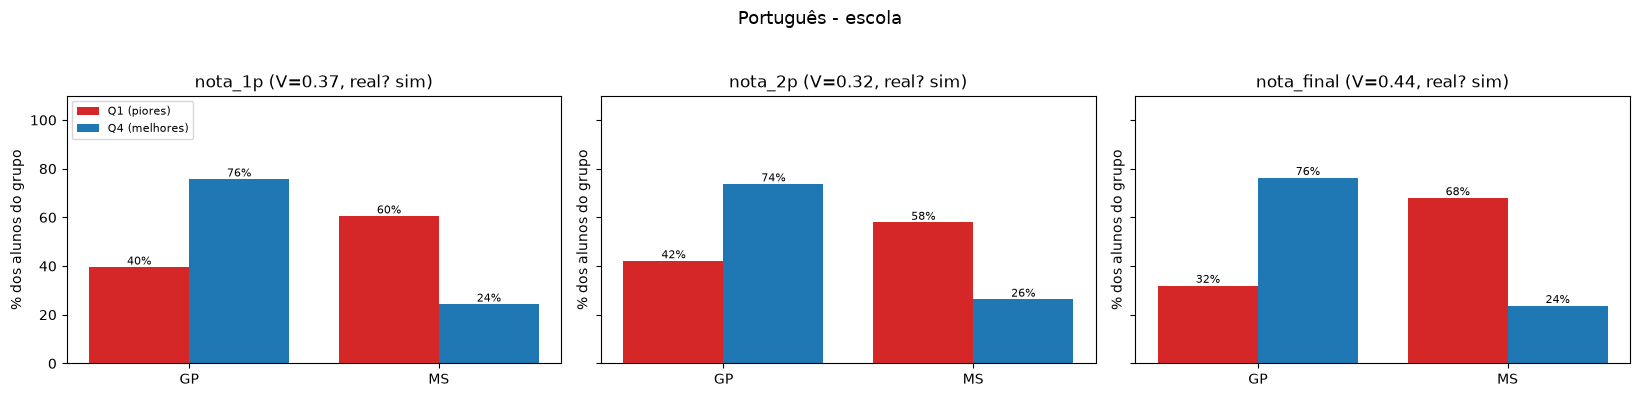

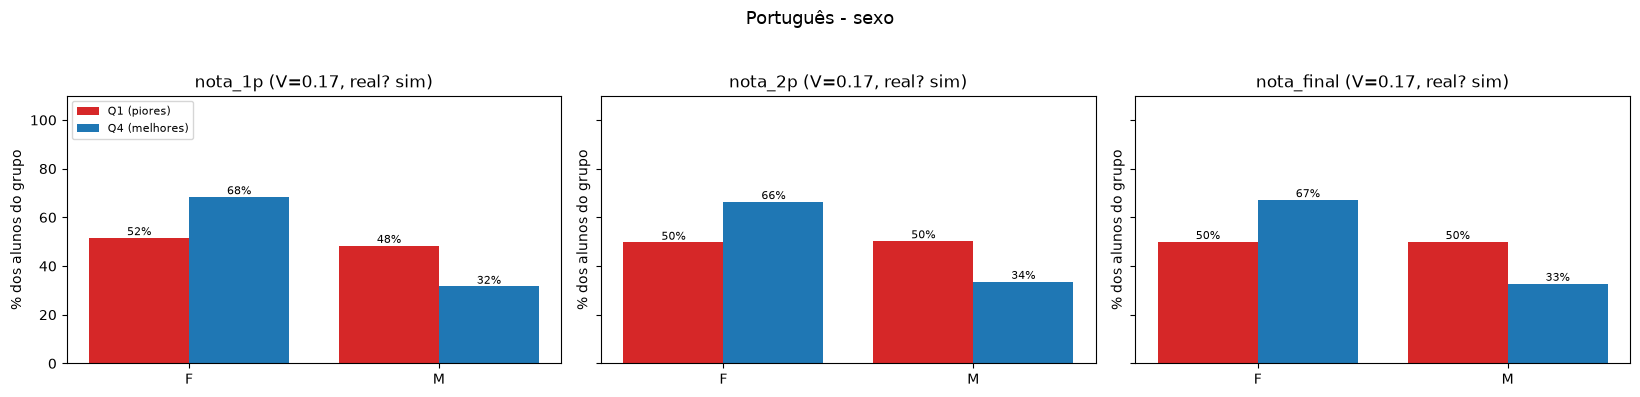

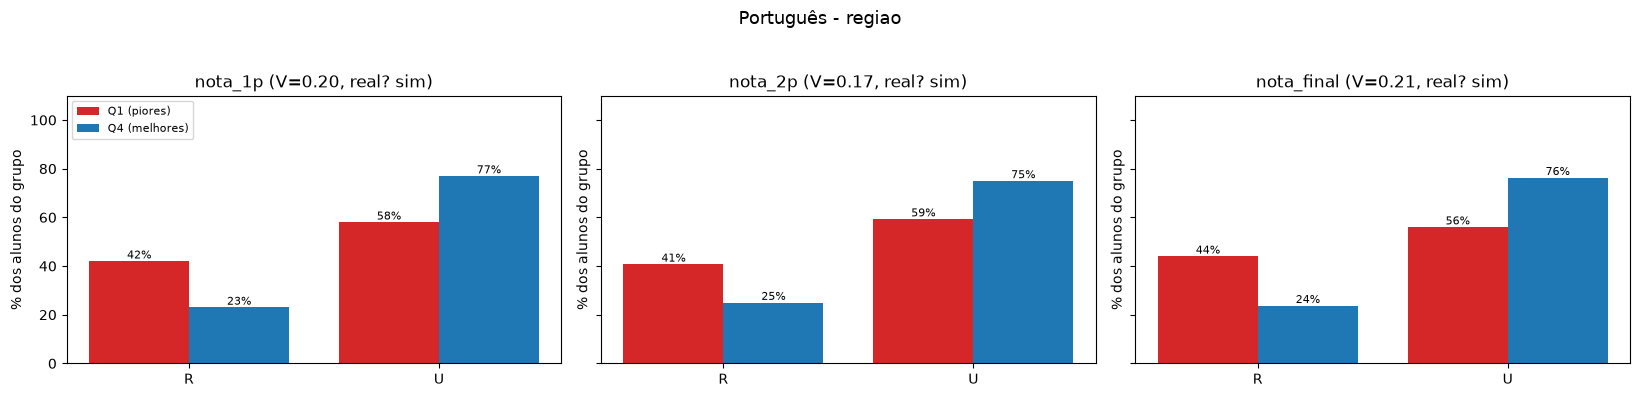

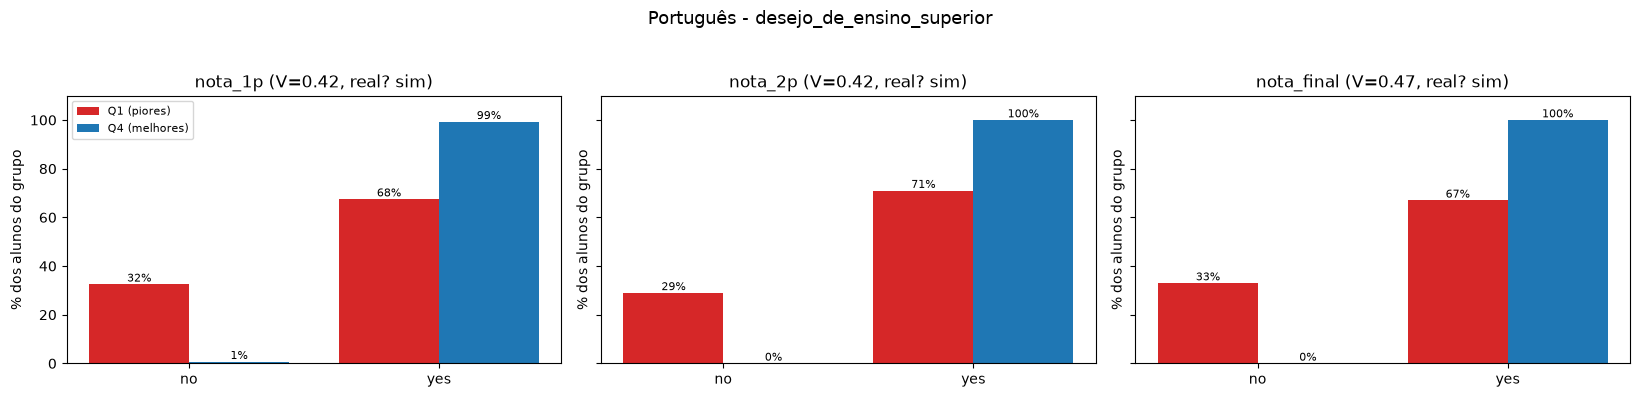

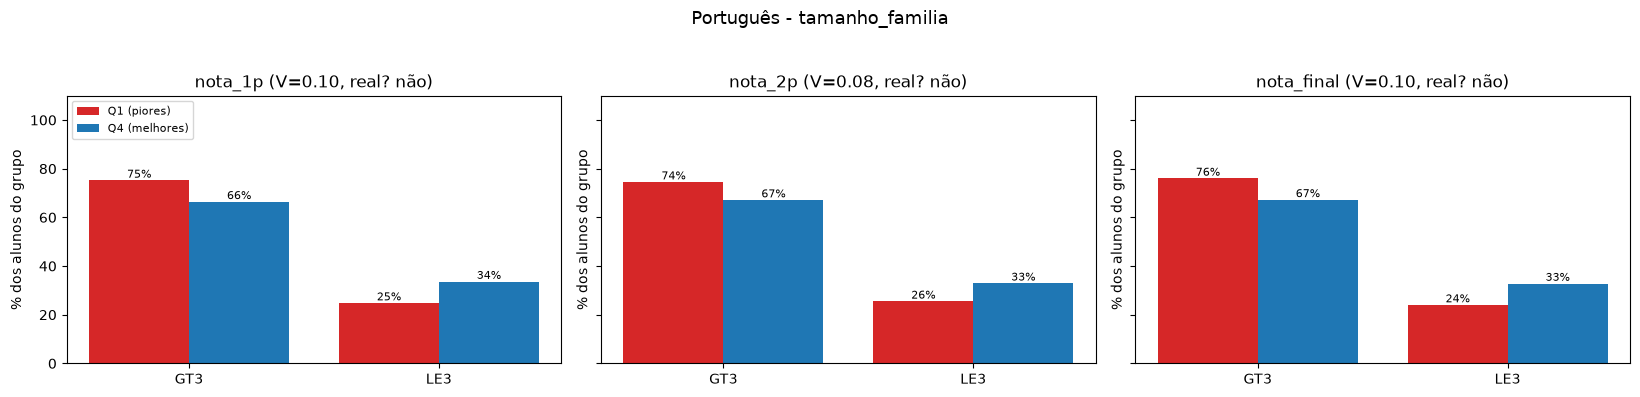

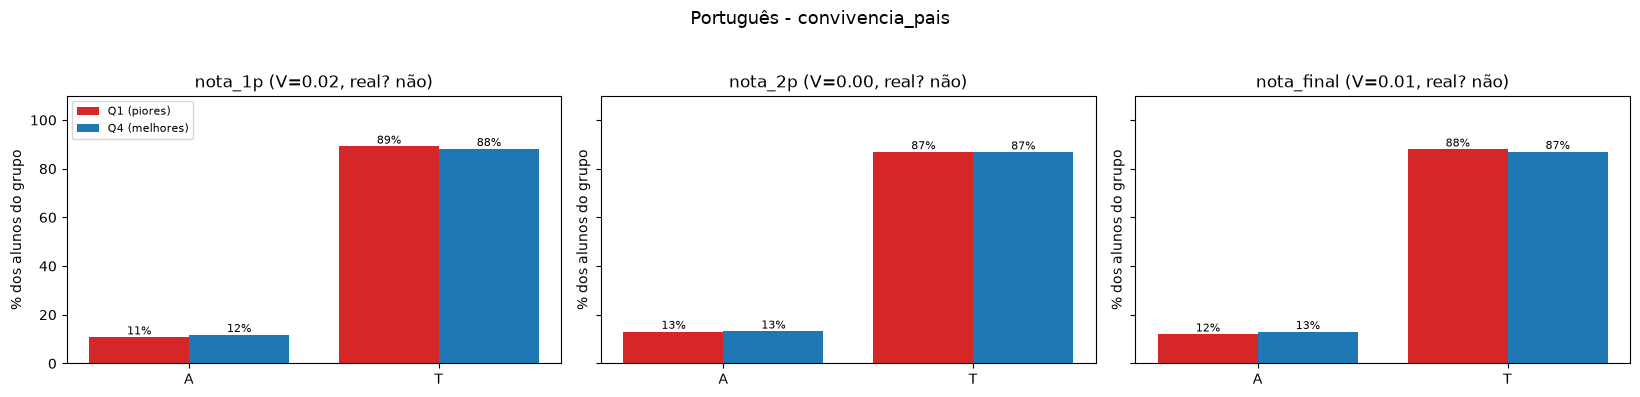

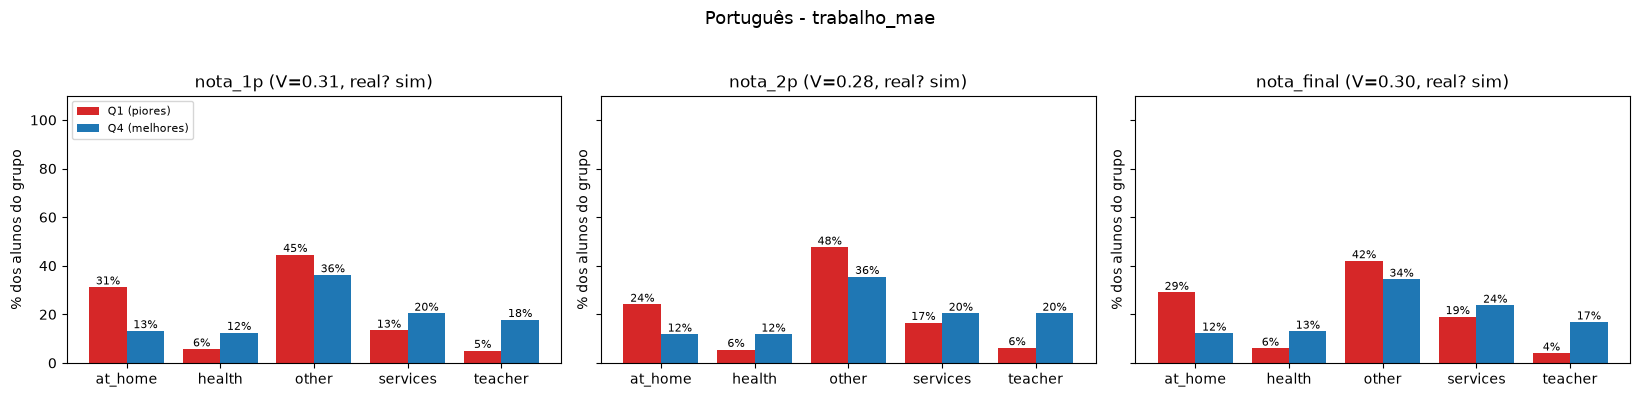

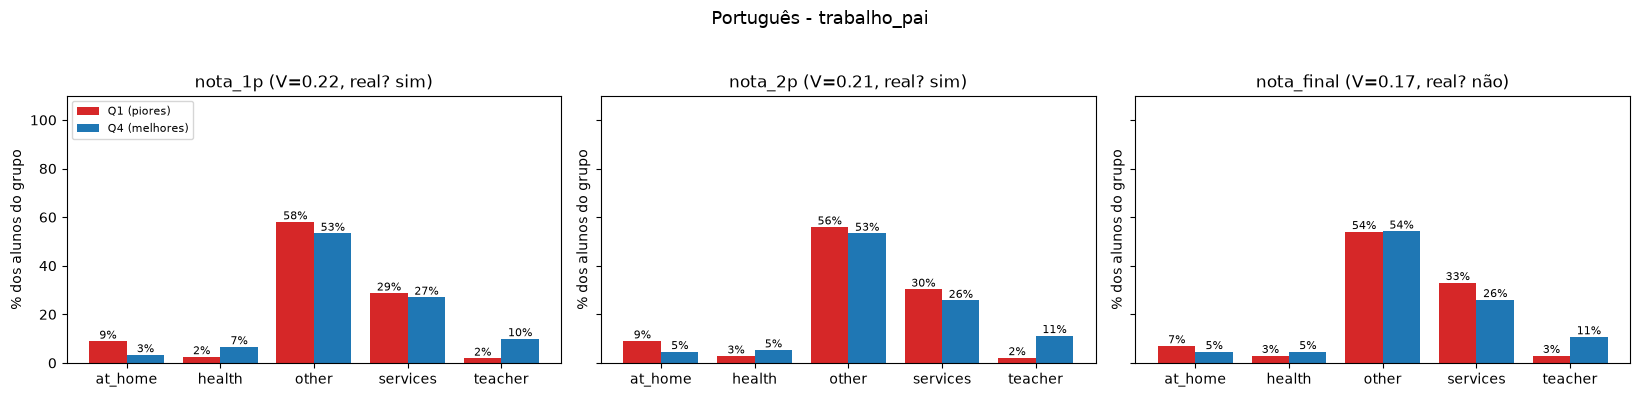

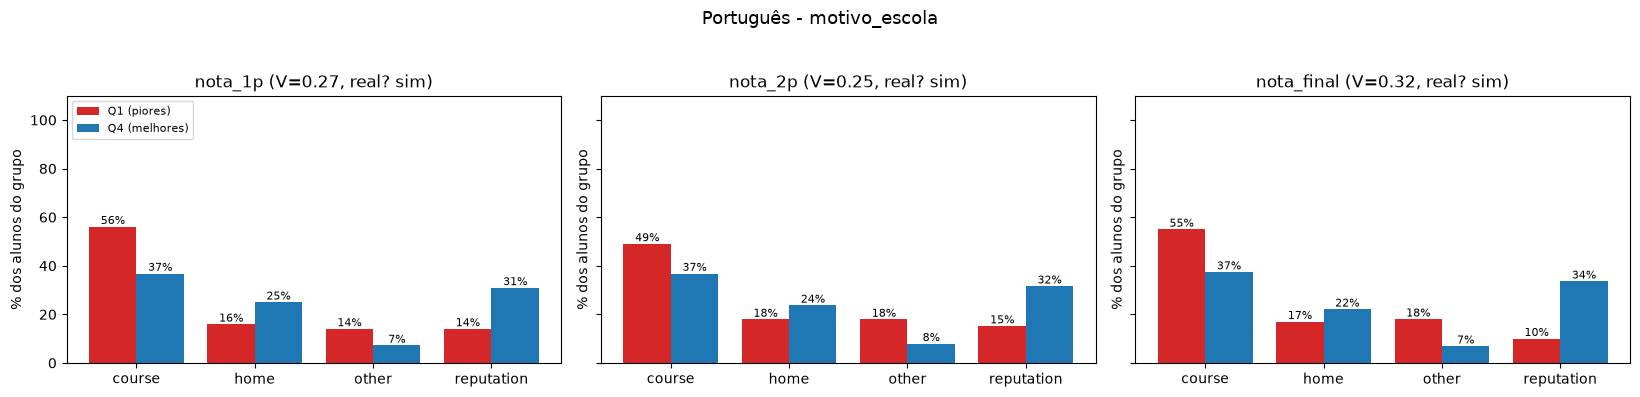

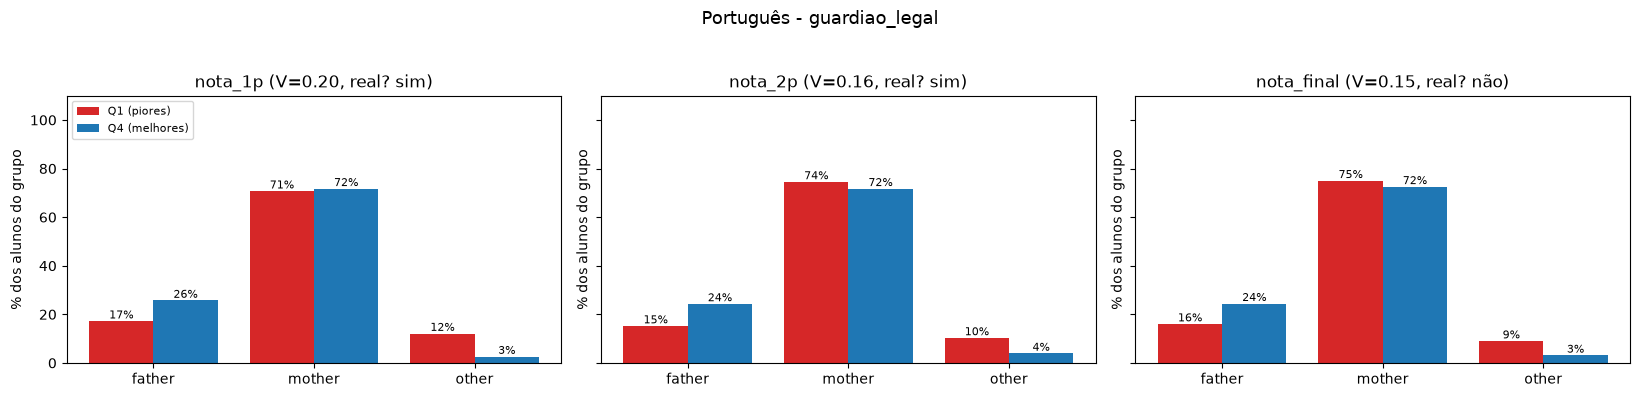

In [7]:
analisar_extremos(df_port, notas, nominais, disciplina="Português")

## Análise por diferença das notas dos quartis Q1 e Q4 - Matemática

Essa análise busca enxergar como as variáveis das colunas se comportam dentro do primeiro e do quarto quartil das notas, por porcentagem. 


Matemática | nota_1p
Q1 (25%) = 8.0 | Q3 (75%) = 13.0 | alunos com nota zero: 0
Grupo Q1 (nota < 8.0): 70 alunos | Grupo Q4 (nota > 13.0): 95 alunos | meio (ignorado): 230

Variáveis ordenadas pelo quanto separam o Q1 do Q4:
                 variavel     V  categoria  %_Q1  %_Q4  dif_pp  p_ajustado real?
             trabalho_mae 0.298      other  42.9  23.2    19.7      0.0287   sim
desejo_de_ensino_superior 0.250         no  15.7   2.1    13.6      0.0160   sim
             trabalho_pai 0.232      other  62.9  44.2    18.6      0.1901   não
                     sexo 0.135          F  60.0  46.3    13.7      0.2349   não
          tamanho_familia 0.134        GT3  78.6  66.3    12.3      0.2750   não
            motivo_escola 0.127 reputation  21.4  31.6   -10.2      0.5749   não
                   regiao 0.095          R  25.7  17.9     7.8      0.3965   não
                   escola 0.075         GP  85.7  90.5    -4.8      0.5749   não
         convivencia_pais 0.058          A   7

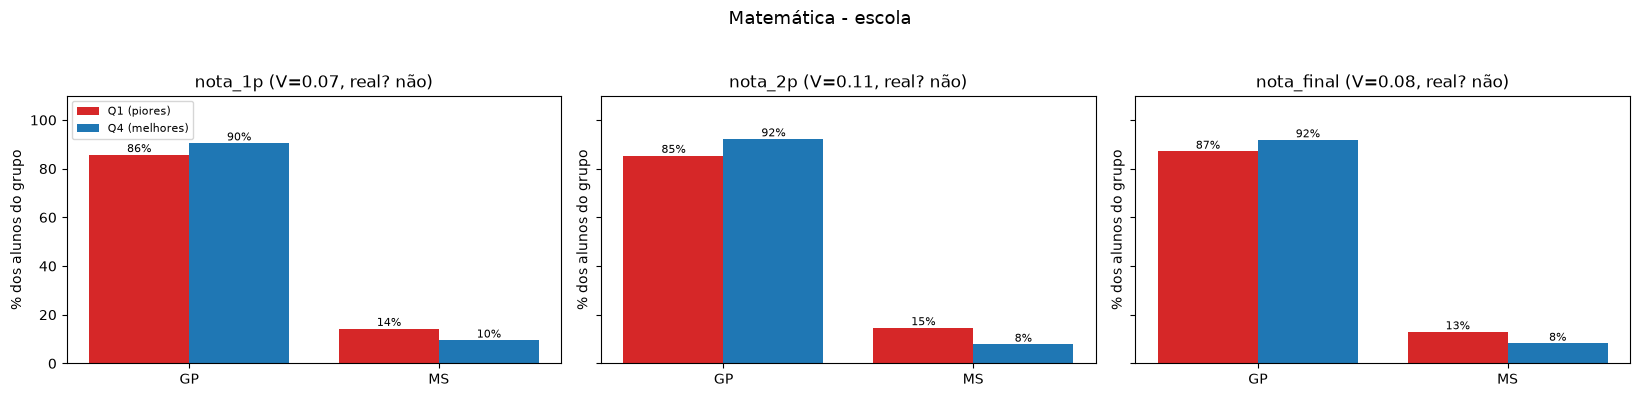

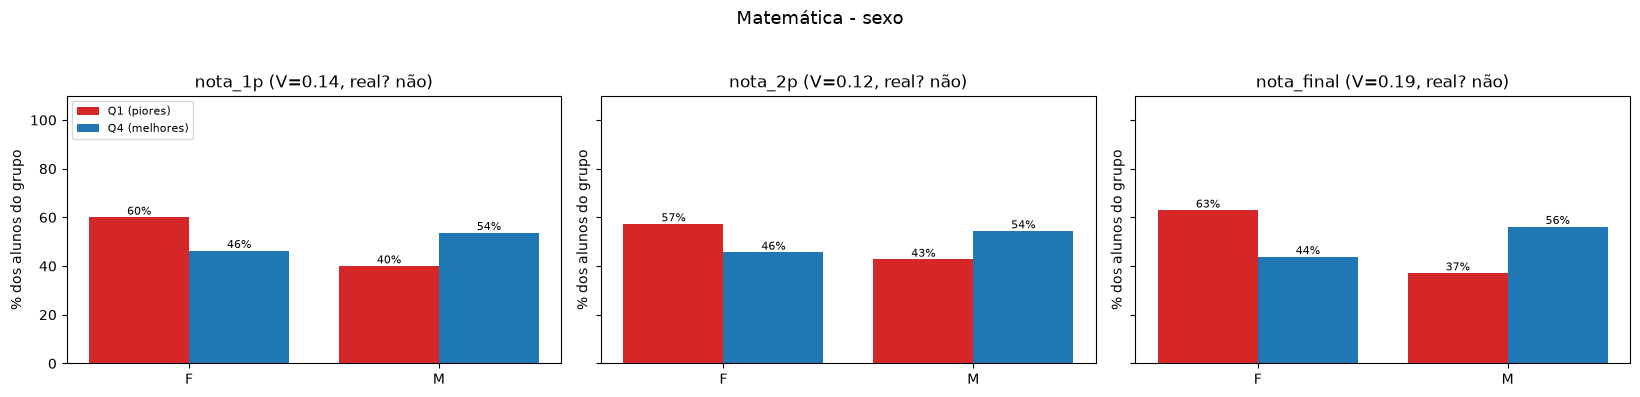

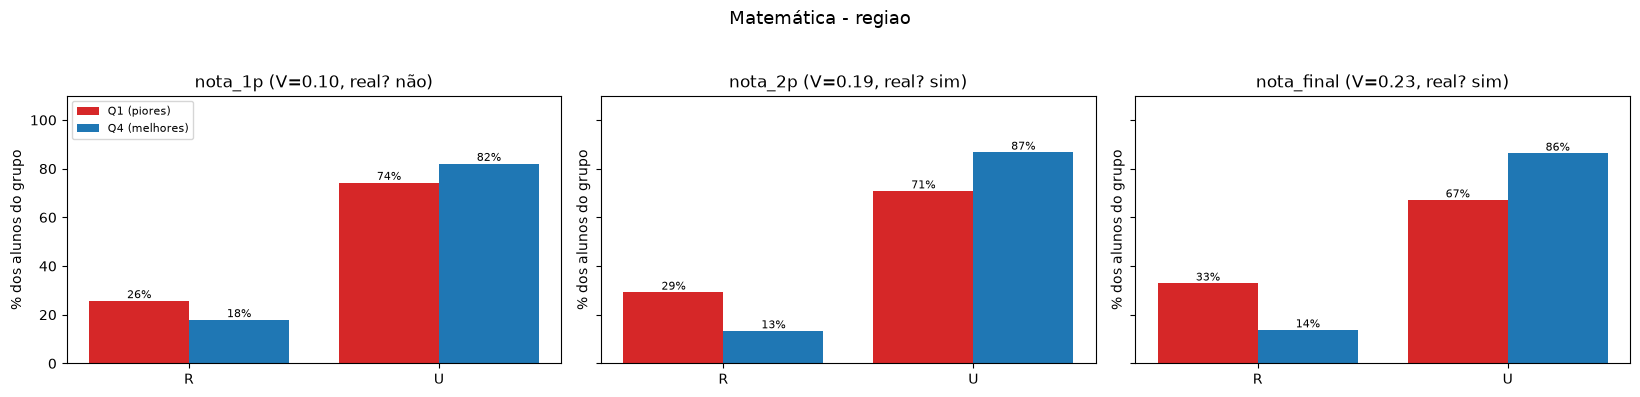

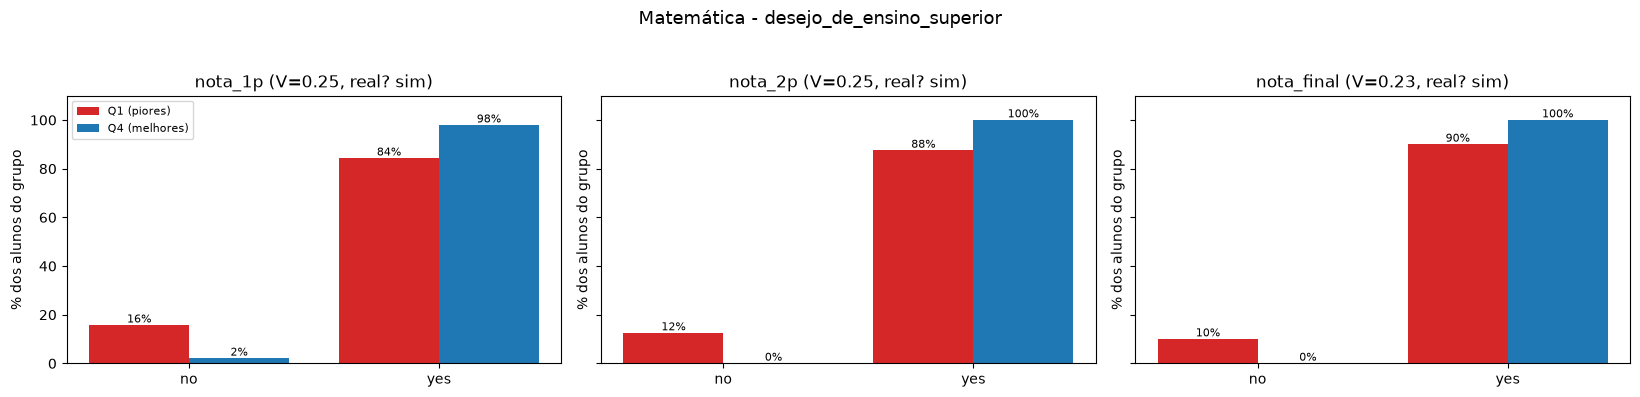

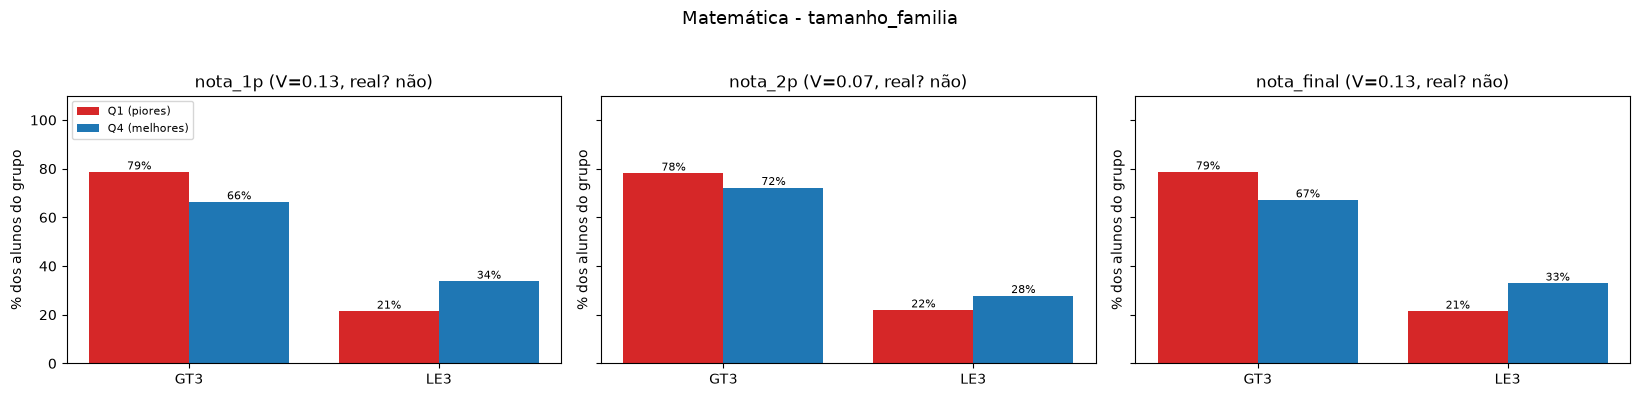

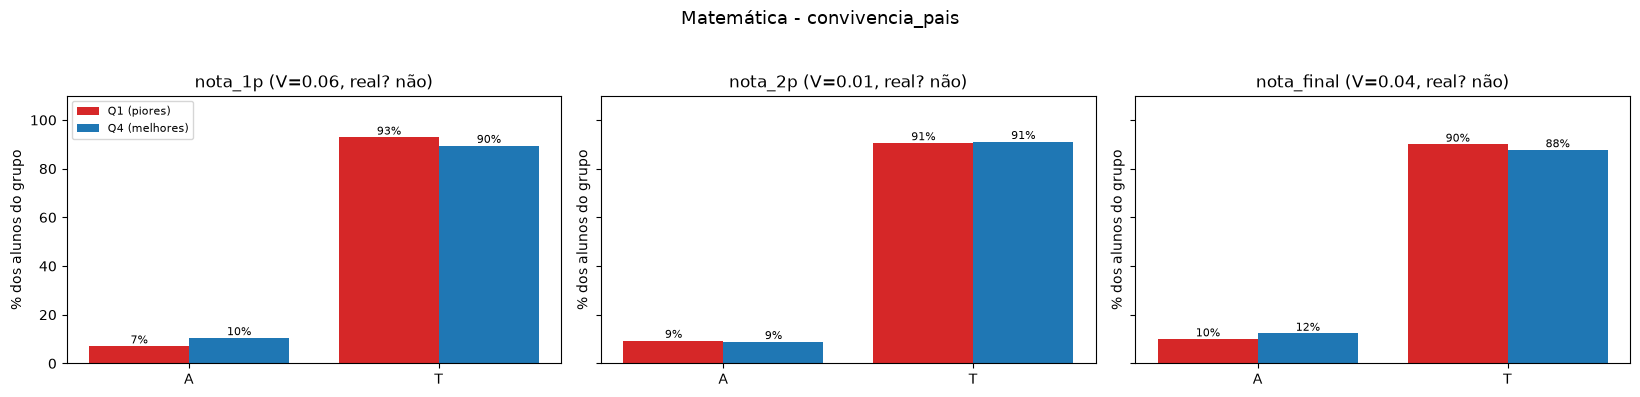

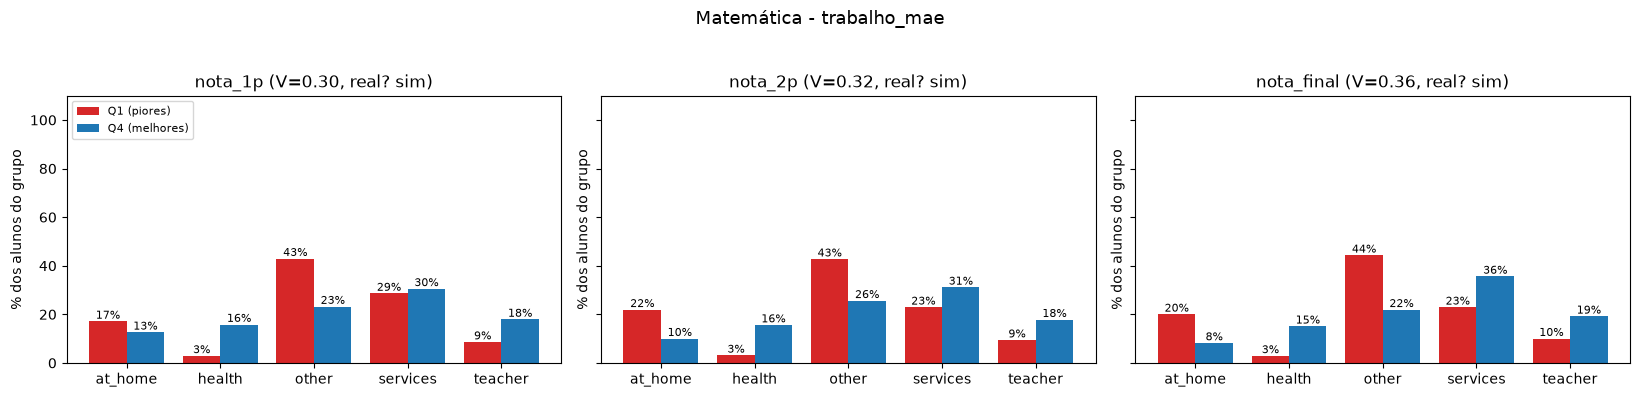

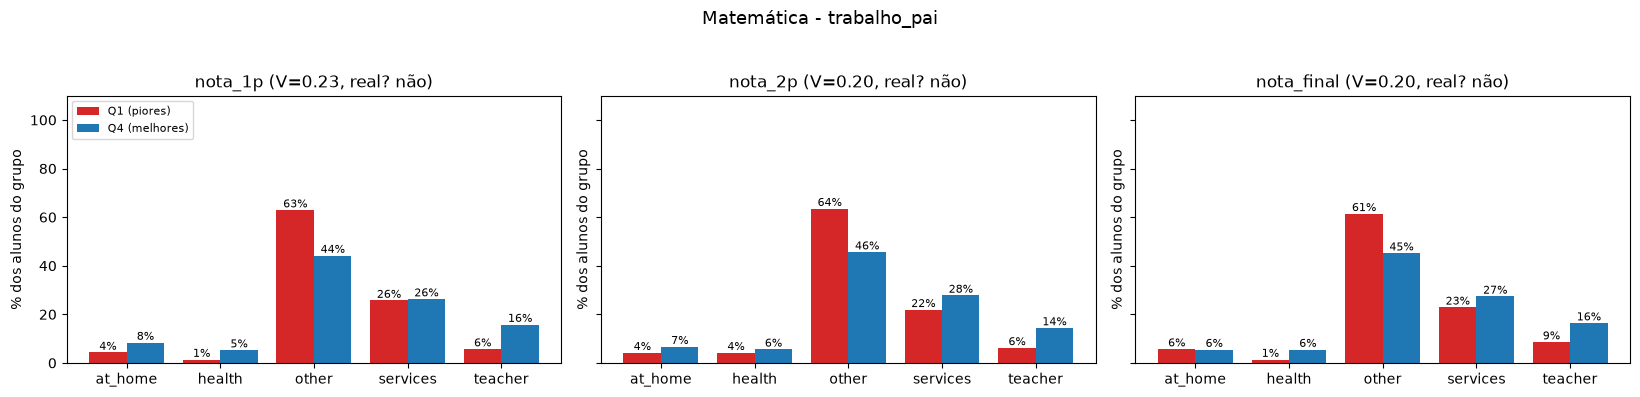

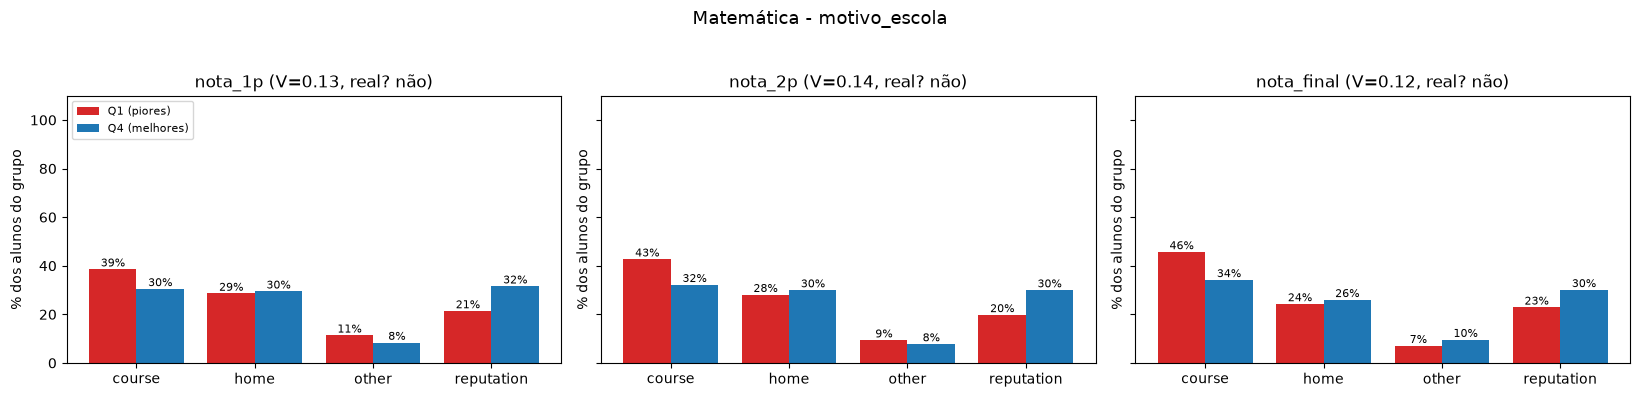

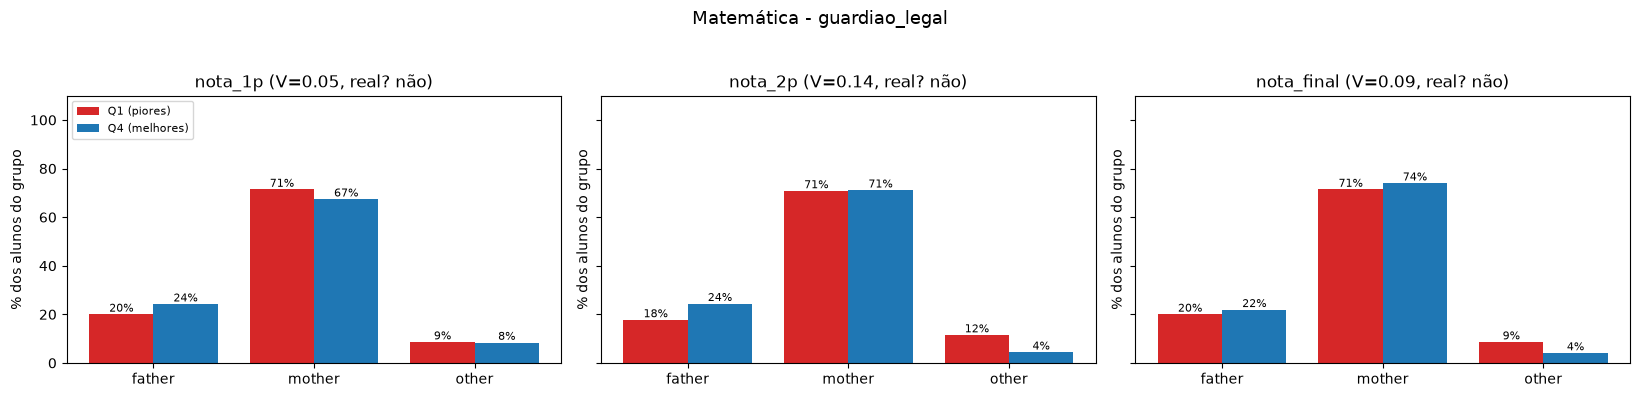

In [8]:
analisar_extremos(df_mat, notas, nominais, disciplina="Matemática")

# MAPA DE CALOR: Relação das variáveis entre si usando V de Cramer

- região ↔ trabalho da mãe e do pai
- escola ↔ região
- desejo de ensino superior ↔ região, escola e sexo


In [34]:
def cramers_v(a, b):
    # tabela de contagens entre as duas variáveis
    tab = pd.crosstab(a, b)
    if tab.shape[0] < 2 or tab.shape[1] < 2:      # uma variável com 1 categoria só
        return np.nan
    chi2 = stats.chi2_contingency(tab, correction=False)[0]
    return np.sqrt(chi2 / tab.values.sum() / (min(tab.shape) - 1))


def mapa_associacoes(df, nominais, titulo="", foco=None, top=10):
    faltando = [c for c in nominais + ([foco] if foco else []) if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    # 1) calcula o V para cada par e monta a matriz
    n = len(nominais)
    matriz = pd.DataFrame(np.eye(n), index=nominais, columns=nominais)
    linhas = []
    for i, a in enumerate(nominais):
        for b in nominais[i + 1:]:
            v = cramers_v(df[a], df[b])
            matriz.loc[a, b] = v
            matriz.loc[b, a] = v
            linhas.append({"variavel_1": a, "variavel_2": b, "V": round(v, 3)})
    pares = pd.DataFrame(linhas).sort_values("V", ascending=False)

    # 2) texto: os pares mais ligados
    print("=" * 60)
    print(f"{titulo} | {len(df)} alunos")
    print("=" * 60)
    print(f"\nOs {top} pares de variáveis mais ligados entre si:")
    print(pares.head(top).to_string(index=False))

    # 3) texto: ligação de cada variável com a variável foco (se você indicar uma)
    if foco:
        print(f"\nAssociação de cada variável com '{foco}':")
        com_foco = pares[(pares["variavel_1"] == foco) | (pares["variavel_2"] == foco)].copy()
        com_foco["outra_variavel"] = np.where(com_foco["variavel_1"] == foco,
                                              com_foco["variavel_2"], com_foco["variavel_1"])
        print(com_foco[["outra_variavel", "V"]].to_string(index=False))

    # 4) mapa de calor (só metade, porque a matriz é simétrica)
    mascara = np.triu(np.ones((n, n), dtype=bool))
    plt.figure(figsize=(9, 7.5))
    sns.heatmap(matriz, mask=mascara, annot=True, fmt=".2f", cmap="Reds",
                vmin=0, vmax=1, linewidths=0.5,
                cbar_kws={"label": "V de Cramér (0 = nenhuma relação, 1 = máxima)"})
    plt.title(f"Relação entre as variáveis nominais - {titulo}")
    plt.tight_layout()
    plt.show()

Português | 649 alunos

Os 10 pares de variáveis mais ligados entre si:
               variavel_1       variavel_2     V
                   escola           regiao 0.355
                   escola    motivo_escola 0.284
                   escola     trabalho_mae 0.242
          tamanho_familia convivencia_pais 0.240
             trabalho_mae     trabalho_pai 0.228
                   regiao     trabalho_mae 0.205
desejo_de_ensino_superior     trabalho_mae 0.200
desejo_de_ensino_superior   guardiao_legal 0.198
                   escola     trabalho_pai 0.181
                   regiao    motivo_escola 0.172

Associação de cada variável com 'desejo_de_ensino_superior':
  outra_variavel     V
    trabalho_mae 0.200
  guardiao_legal 0.198
          escola 0.136
   motivo_escola 0.127
    trabalho_pai 0.117
          regiao 0.077
            sexo 0.058
convivencia_pais 0.023
 tamanho_familia 0.005


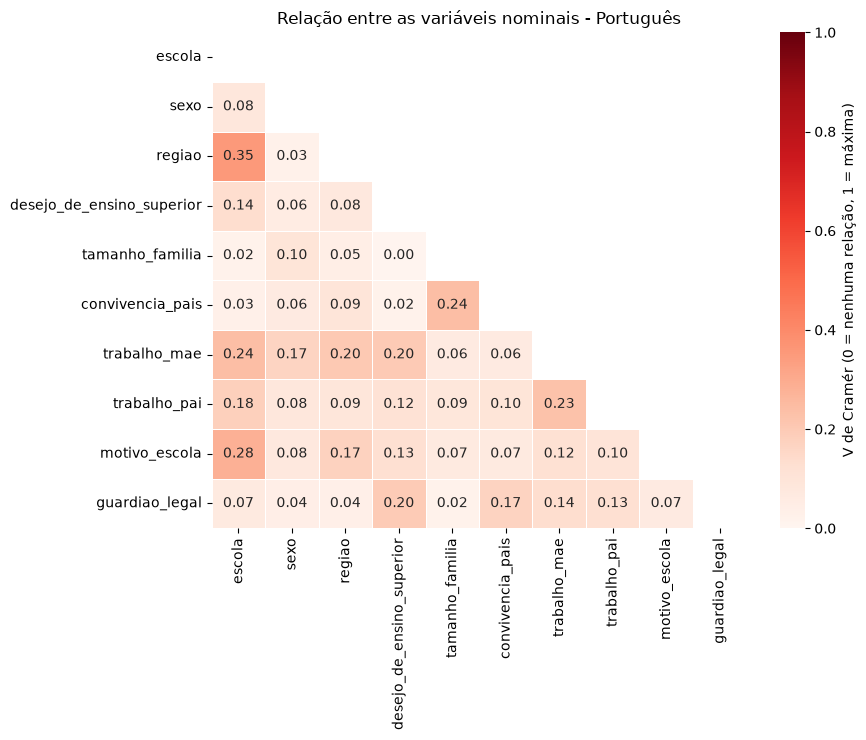

Matemática | 395 alunos

Os 10 pares de variáveis mais ligados entre si:
               variavel_1                variavel_2     V
                   escola                    regiao 0.280
             trabalho_mae              trabalho_pai 0.216
                     sexo              trabalho_mae 0.210
                   regiao              trabalho_mae 0.183
                   escola             motivo_escola 0.178
desejo_de_ensino_superior             motivo_escola 0.161
                   regiao             motivo_escola 0.156
                     sexo desejo_de_ensino_superior 0.151
desejo_de_ensino_superior              trabalho_mae 0.150
          tamanho_familia          convivencia_pais 0.150

Associação de cada variável com 'desejo_de_ensino_superior':
  outra_variavel     V
   motivo_escola 0.161
            sexo 0.151
    trabalho_mae 0.150
    trabalho_pai 0.096
          regiao 0.043
convivencia_pais 0.041
          escola 0.024
  guardiao_legal 0.021
 tamanho_familia 0.0

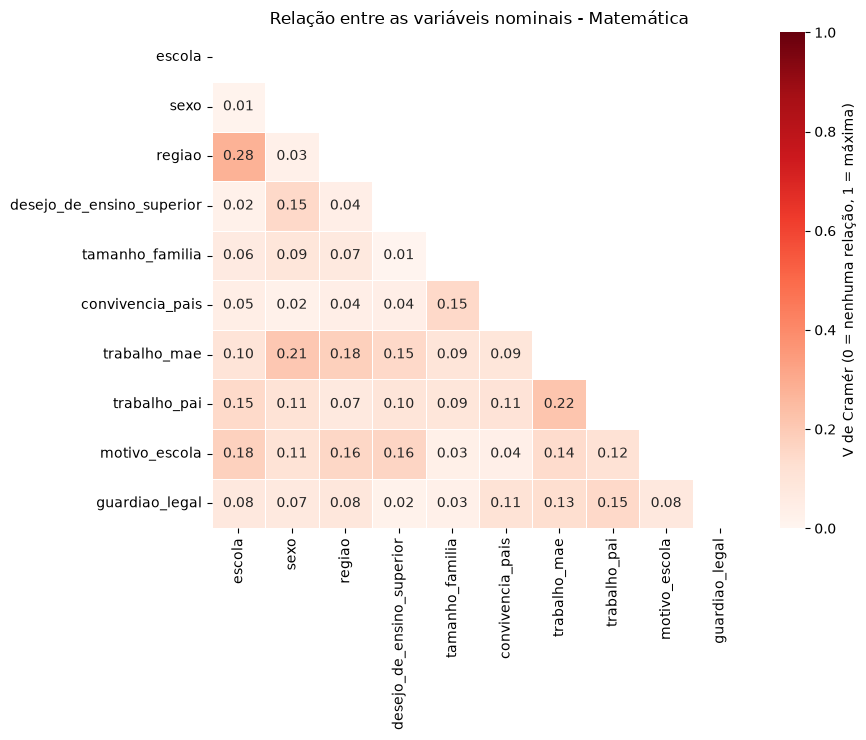

In [35]:
nominais = ["escola", "sexo", "regiao", "desejo_de_ensino_superior", "tamanho_familia",
            "convivencia_pais", "trabalho_mae", "trabalho_pai", "motivo_escola", "guardiao_legal"]

mapa_associacoes(df_port, nominais, titulo="Português", foco="desejo_de_ensino_superior")
mapa_associacoes(df_mat, nominais, titulo="Matemática", foco="desejo_de_ensino_superior")

# RELAÇÃO DAS VARIÁVEIS NOMINAIS COM AS NOTAS:

In [ ]:
def ajustar_bh(p):
    # correção para vários testes (Benjamini-Hochberg)
    p = np.asarray(p, dtype=float)
    n = len(p)
    ordem = np.argsort(p)
    ajustado = np.empty(n)
    minimo = 1.0
    for i in range(n - 1, -1, -1):
        idx = ordem[i]
        minimo = min(minimo, p[idx] * n / (i + 1))
        ajustado[idx] = minimo
    return ajustado


def relacao_com_notas(df, col_notas, nominais, disciplina=""):
    faltando = [c for c in col_notas + nominais if c not in df.columns]
    if faltando:
        print("ATENÇÃO - estas colunas não existem no seu DataFrame:", faltando)
        print("Colunas disponíveis:", list(df.columns))
        return

    # 1) para cada variável e cada nota: teste de Kruskal-Wallis + tamanho do efeito
    linhas = []
    for nota in col_notas:
        for col in nominais:
            grupos = [g[nota].values for _, g in df.groupby(col)]
            if len(grupos) < 2:
                continue
            h, p = stats.kruskal(*grupos)
            n = sum(len(g) for g in grupos)
            eps2 = h / ((n ** 2 - 1) / (n + 1))          # tamanho do efeito (epsilon²)
            medias = df.groupby(col)[nota].mean()
            linhas.append({
                "nota": nota, "variavel": col,
                "tamanho_efeito": round(max(eps2, 0), 3), "p": p,
                "categoria_maior_media": medias.idxmax(), "media_maior": round(medias.max(), 1),
                "categoria_menor_media": medias.idxmin(), "media_menor": round(medias.min(), 1),
                "n_menor_grupo": int(df[col].value_counts().min()),
            })
    res = pd.DataFrame(linhas)
    res["p_ajustado"] = ajustar_bh(res["p"]).round(4)
    res["real?"] = np.where(res["p_ajustado"] < 0.05, "sim", "não")

    # 2) texto: tabela resumo (variável x nota)
    efeito = res.pivot(index="variavel", columns="nota", values="tamanho_efeito")[col_notas]
    efeito = efeito.loc[efeito.mean(axis=1).sort_values(ascending=False).index]
    real = res.pivot(index="variavel", columns="nota", values="real?")[col_notas].loc[efeito.index]
    anot = efeito.round(3).astype(str) + real.map(lambda x: "*" if x == "sim" else "")

    print("=" * 70)
    print(f"{disciplina}: relação de cada variável com as notas")
    print("(tamanho do efeito; * = diferença que não parece acaso)")
    print("=" * 70)
    print(anot.to_string())

    print("\nDetalhe: categoria com a maior e a menor média de nota")
    detalhe = res[["nota", "variavel", "tamanho_efeito", "p_ajustado", "real?",
                   "categoria_maior_media", "media_maior", "categoria_menor_media",
                   "media_menor", "n_menor_grupo"]]
    print(detalhe.sort_values(["nota", "tamanho_efeito"], ascending=[True, False]).to_string(index=False))

    # 3) gráfico: mapa de calor do tamanho do efeito
    plt.figure(figsize=(7, 0.55 * len(efeito) + 2))
    sns.heatmap(efeito, annot=anot, fmt="", cmap="Reds", vmin=0, vmax=0.15,
                linewidths=0.5, cbar_kws={"label": "tamanho do efeito (0 = nenhum)"})
    plt.title(f"{disciplina}: quanto cada variável se relaciona com as notas\n(* = não parece acaso)")
    plt.ylabel("")
    plt.xlabel("")
    plt.tight_layout()
    plt.show()
    return res

nominais = ["escola", "sexo", "regiao", "desejo_de_ensino_superior", "tamanho_familia",
            "convivencia_pais", "trabalho_mae", "trabalho_pai", "motivo_escola", "guardiao_legal"]
notas = ["nota_1p", "nota_2p", "nota_final"]

# Portguês:

Português: relação de cada variável com as notas
(tamanho do efeito; * = diferença que não parece acaso)
nota                      nota_1p nota_2p nota_final
variavel                                            
desejo_de_ensino_superior  0.129*   0.12*     0.125*
escola                     0.091*  0.072*     0.081*
trabalho_mae               0.055*  0.051*     0.057*
motivo_escola              0.045*  0.049*     0.049*
trabalho_pai               0.034*   0.03*     0.027*
regiao                     0.027*  0.026*     0.029*
guardiao_legal             0.022*  0.014*     0.012*
sexo                       0.014*  0.015*     0.018*
tamanho_familia             0.002   0.001        0.0
convivencia_pais              0.0     0.0        0.0

Detalhe: categoria com a maior e a menor média de nota
      nota                  variavel  tamanho_efeito  p_ajustado real? categoria_maior_media  media_maior categoria_menor_media  media_menor  n_menor_grupo
   nota_1p desejo_de_ensino_superior           

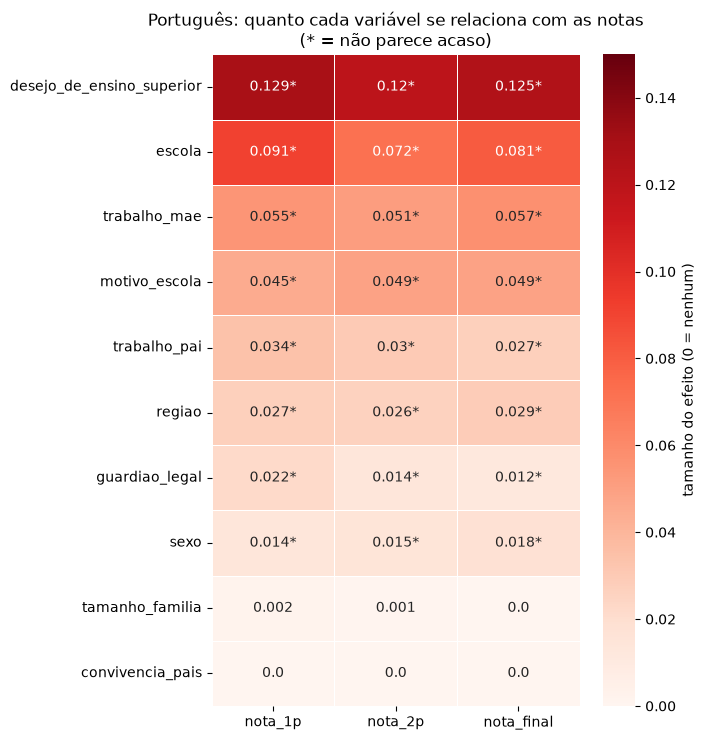

In [44]:
res_port = relacao_com_notas(df_port, notas, nominais, disciplina="Português")

# Matemática:

Matemática: relação de cada variável com as notas
(tamanho do efeito; * = diferença que não parece acaso)
nota                      nota_1p nota_2p nota_final
variavel                                            
trabalho_mae               0.043*  0.042*     0.041*
desejo_de_ensino_superior  0.033*  0.034*      0.03*
trabalho_pai                0.031   0.017      0.016
regiao                      0.006  0.016*      0.014
motivo_escola               0.011   0.012      0.012
sexo                        0.009    0.01      0.011
guardiao_legal              0.002   0.009       0.01
tamanho_familia             0.005   0.006      0.004
escola                      0.001   0.004      0.004
convivencia_pais              0.0   0.001      0.002

Detalhe: categoria com a maior e a menor média de nota
      nota                  variavel  tamanho_efeito  p_ajustado real? categoria_maior_media  media_maior categoria_menor_media  media_menor  n_menor_grupo
   nota_1p              trabalho_mae          

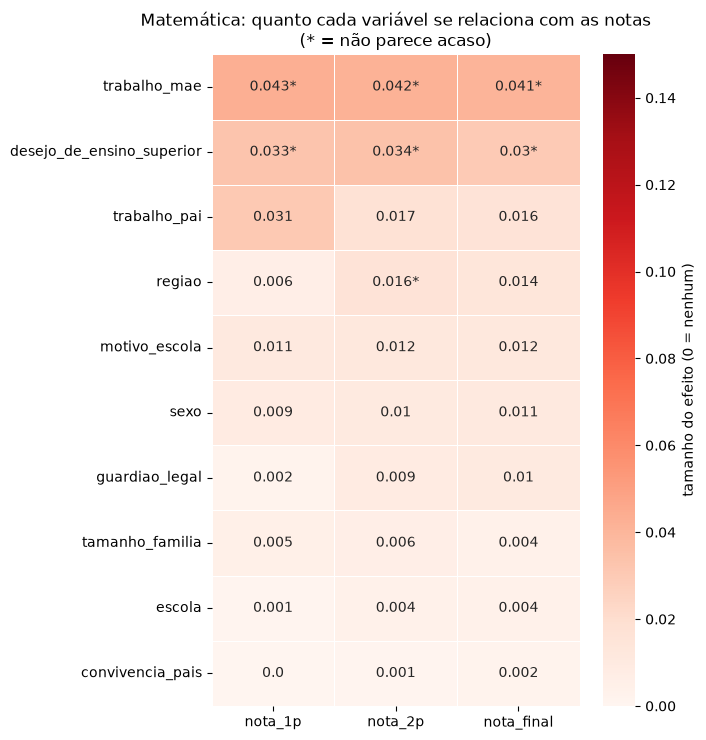

In [40]:
res_mat = relacao_com_notas(df_mat, notas, nominais, disciplina="Matemática")